# Customer Churn Intelligence

A practical analysis of customer behaviour, customer segments and churn risk.

This notebook combines statistical analysis, unsupervised learning and
predictive modelling to investigate:

1. How customer characteristics differ between customers who stay and leave.
2. Whether meaningful customer segments emerge without using churn labels.
3. How reliably machine learning models predict churn.
4. Which features influence model predictions.
5. How predicted risk can support customer prioritization.

## Analysis Plan

- **Data quality:** Check missing values, data types, duplicates and consistency.
- **Exploratory analysis:** Examine customer characteristics and churn patterns.
- **Statistical analysis:** Quantify associations using effect sizes,
  confidence intervals and appropriate tests.
- **Customer segmentation:** Discover and profile groups using customer
  characteristics, then compare their observed churn rates.
- **Predictive modelling:** Compare a simple baseline with CatBoost.
- **Probability calibration:** Assess whether predicted risks match observed outcomes.
- **Explainability:** Examine global and individual predictions using SHAP.
- **Prioritization:** Evaluate how many churners are captured within
  different outreach capacities.

## Interpretation Boundaries

The data represents a fictional telecom company. Associations and model
explanations do not establish causation or prove that a retention intervention
will succeed.

Customer identifiers and churn labels will be excluded from clustering.
Predictive preprocessing and model selection will use training and validation
data, with a held-out test set reserved for final evaluation.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display 

SEED = 42

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (10,5),
    "axes.spines.top": False, 
    "axes.spines.right": False,
})

In [2]:
csv_files = sorted(
    Path("/kaggle/input").rglob("*.csv")
)

print(f"Found {len(csv_files)} CSV file(s):\n")

for path in csv_files:
    print(path)

if not csv_files:
    raise FileNotFoundError(
        "No CSV files found. Attach the dataset and rerun this cell."
    )

Found 1 CSV file(s):

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [3]:
filename = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

matches = [
    path for path in csv_files
    if path.name.casefold() == filename.casefold()
]

if len(matches) != 1:
    raise ValueError("Only 1 file is expected")

data_path = matches[0]

df_raw = pd.read_csv(data_path)
df = df_raw.copy(deep=True)

print(f"Loaded: {data_path.name}")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")

display(df.head())

Loaded: WA_Fn-UseC_-Telco-Customer-Churn.csv
Rows: 7,043
Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Data Quality and Structure

Before analysing customer behaviour, we inspect the dataset's structure
and identify potential quality issues.

The checks cover:
- Column types and sample values
- Missing values and blank strings
- Duplicate rows and customer identifiers
- Target labels and class balance
- Numeric conversion issues

At this stage, issues are reported before any rows or values are changed.

In [4]:
blank_counts = pd.Series(0, index = df.columns, dtype = "int64")

text_columns = df.select_dtypes(
    include = ["object", "string"]
).columns

for column in text_columns:
    blank_counts[column] = int(
        df[column]
        .astype("string")
        .str.strip()
        .eq("")
        .fillna(False)
        .sum()
    )

quality_report = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "blank_strings": blank_counts,
    "unique_non_null": df.nunique(dropna = True)
})

quality_report["missing_or_blank_pct"] = (
    100 * (quality_report["missing"] + quality_report["blank_strings"]) / len(df)
).round(2)

quality_report["sample_values"] = [
    df[column].dropna().unique()[:4].tolist()
    for column in df.columns
]

display(quality_report)

print(
    "\n Fully duplicated rows:", int(df.duplicated().sum())
)

if "customerID" in df.columns:
    print(
        "Missing customer IDs:",
        int(df["customerID"].isna().sum())
    )

    print(
        "Repeated non-null customer IDs:",
        int(
            df.loc[df["customerID"].notna(), "customerID"]
            .duplicated()
            .sum()
        )
    )

,dtype,missing,blank_strings,unique_non_null,missing_or_blank_pct,sample_values
customerID,object,0,0,7043,0.00,"[7590-VHVEG, 5575-GNVDE, 3668-QPYBK, 7795-CFOCW]"
gender,object,0,0,2,0.00,"[Female, Male]"
SeniorCitizen,int64,0,0,2,0.00,"[0, 1]"
Partner,object,0,0,2,0.00,"[Yes, No]"
Dependents,object,0,0,2,0.00,"[No, Yes]"
tenure,int64,0,0,73,0.00,"[1, 34, 2, 45]"
PhoneService,object,0,0,2,0.00,"[No, Yes]"
MultipleLines,object,0,0,3,0.00,"[No phone service, No, Yes]"
InternetService,object,0,0,3,0.00,"[DSL, Fiber optic, No]"
OnlineSecurity,object,0,0,3,0.00,"[No, Yes, No internet service]"



 Fully duplicated rows: 0
Missing customer IDs: 0
Repeated non-null customer IDs: 0


In [5]:
required_columns = {
    "customerID",
    "Churn",
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
}

missing_columns = required_columns.difference(df.columns)

if missing_columns:
    raise ValueError(
        f"Expected columns are missing: {sorted(missing_columns)}"
    )

total_charges_text = (
    df["TotalCharges"]
    .astype("string")
    .str.strip()
)

total_charges_numeric = pd.to_numeric(
    total_charges_text,
    errors = "coerce"
)

nonblank = (
    total_charges_text.notna()
    & total_charges_text.ne("")
)

invalid_numeric = (
    nonblank
    & total_charges_numeric.isna()
)

print(
    "Missing or blank TotalCharges:",
    int((~nonblank).sum())
)

print(
    "Nonblank TotalCharges values that canoot be converted:", 
    int(invalid_numeric.sum())
)

problem_rows = total_charges_numeric.isna()

if problem_rows.any():
    display(
        df.loc[
            problem_rows,
            [
                "customerID",
                "tenure",
                "MonthlyCharges",
                "TotalCharges",
                "Churn",
            ]
        ].head(20)
    )

numeric_preview = df[
    ["tenure", "MonthlyCharges"]
].apply(pd.to_numeric, errors="coerce")

numeric_preview["TotalCharges"] = total_charges_numeric

display(numeric_preview.describe().T)

print("\nNegative-value checks:")
display(
    numeric_preview.lt(0)
    .sum()
    .rename("negative_count")
    .to_frame()
)

Missing or blank TotalCharges: 11
Nonblank TotalCharges values that canoot be converted: 0


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.8,401.45,1397.475,3794.7375,8684.8



Negative-value checks:


,negative_count
tenure,0
MonthlyCharges,0
TotalCharges,0


Observed Churn labels:
['No' 'Yes']


,customers,percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


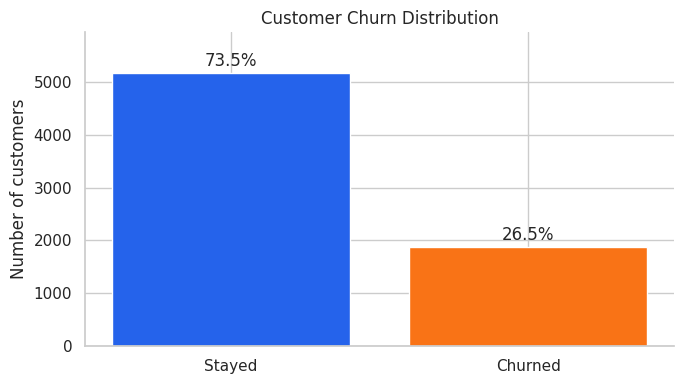

In [6]:
print("Observed Churn labels:")
print(df["Churn"].unique())

churn_labels = (
    df["Churn"]
    .astype("string")
    .str.strip()
)

unexpected_labels = (
    churn_labels.notna()
    & ~churn_labels.isin(["Yes", "No"])
)

if churn_labels.isna().any() or unexpected_labels.any():
    raise ValueError(
        "Churn contains missing or unexpected labels. "
        "Inspect them before continuing."
    )

churn_summary = (
    churn_labels.value_counts()
    .reindex(["No", "Yes"], fill_value=0)
    .rename_axis("Churn")
    .to_frame("customers")
)

churn_summary["percentage"] = (
    100 * churn_summary["customers"] / len(df)
).round(2)

display(churn_summary)

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    ["Stayed", "Churned"],
    churn_summary["customers"],
    color=["#2563EB", "#F97316"],
)

for bar, percentage in zip(
    bars,
    churn_summary["percentage"],
):
    ax.annotate(
        f"{percentage:.1f}%",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
    )

ax.set_title("Customer Churn Distribution")
ax.set_ylabel("Number of customers")
ax.set_ylim(
    0,
    max(churn_summary["customers"]) * 1.15
)

plt.tight_layout()
plt.show()

### Initial Data Quality Findings

The dataset contains 7,043 customers, of whom 1,869 (26.54%) churned.

`TotalCharges` contains 11 blank entries. All 11 occur among customers
with zero recorded tenure. These records are retained, and the blank
charges are represented as missing values rather than assumed to be zero.

No nonblank numeric-conversion failures were detected in `TotalCharges`.
No negative values were found in tenure, monthly charges or total charges.

The target distribution is moderately imbalanced. Model evaluation will
therefore include discrimination, probability quality and customer-ranking
metrics rather than relying on accuracy alone.

In [7]:
df = df_raw.copy(deep=True)

text_columns = df.select_dtypes(
    include = ["object", "string"]
).columns

for column in text_columns:
    df[column] = (
        df[column]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
    )

numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors = "raise",
    ).astype("float64")

if df["Churn"].isna().any():
    raise ValueError("Missing churn labels require investigation.")

if not df["Churn"].isin(["No", "Yes"]).all():
    raise ValueError("Unexpected churn labels require investigation.")

df["ChurnFlag"] = (
    df["Churn"]
    .map({"No":0, "Yes":1})
    .astype("int64")
)

if df["customerID"].isna().any():
    raise ValueError("Missing customer IDs require investigation.")

if df["customerID"].duplicated().any():
    raise ValueError("Repeated customer IDs require investigation.")

print(f"Customers retained: {len(df):,}")

print("\nNumerical column types:")
print(df[numeric_columns].dtypes)

print("\nMissing numerical values:")
print(df[numeric_columns].isna().sum())

Customers retained: 7,043

Numerical column types:
tenure            float64
MonthlyCharges    float64
TotalCharges      float64
dtype: object

Missing numerical values:
tenure             0
MonthlyCharges     0
TotalCharges      11
dtype: int64


## 2. Development and Evaluation Strategy

Customers are divided into training (60%), validation (20%) and test
(20%) sets, preserving approximately the same churn proportion in each.

Exploratory analysis, statistical comparisons and initial customer
segmentation will use the training set. Validation data will support
model selection and development decisions. Test data will be reserved
for final evaluation.

Because this dataset does not provide a suitable observation timeline,
the random split evaluates generalisation to held-out customers from
this sample; it does not demonstrate performance on future customers.

In [8]:
from sklearn.model_selection import train_test_split

development_df, test_df = train_test_split(
    df,
    test_size = 0.20,
    stratify = df["ChurnFlag"],
    random_state = SEED,
)

train_df, valid_df = train_test_split(
    development_df,
    test_size = 0.25,
    stratify = development_df["ChurnFlag"],
    random_state = SEED,
)

train_df = train_df.copy()
valid_df = valid_df.copy()
test_df = test_df.copy()

split_summary = pd.DataFrame({
    "split": ["Training", "Validation", "Test"],
    "customers": [len(train_df), len(valid_df), len(test_df)],
})

split_summary["share_pct"] = (
    100 * split_summary["customers"] / len(df)
).round(2)

display(split_summary)

train_ids = set(train_df["customerID"])
valid_ids = set(valid_df["customerID"])
test_ids = set(test_df["customerID"])

assert train_ids.isdisjoint(valid_ids)
assert train_ids.isdisjoint(test_ids)
assert valid_ids.isdisjoint(test_ids)

assert len(train_df) + len(valid_df) + len(test_df) == len(df)

print("Checks passed: splits contain distinct customers.")

,split,customers,share_pct
0,Training,4225,59.99
1,Validation,1409,20.01
2,Test,1409,20.01


Checks passed: splits contain distinct customers.


## 3. Exploring Customer Behaviour

We begin by comparing tenure and monthly charges between customers who
stayed and those who churned.

The analysis uses the training set. We examine both summary statistics
and distributions because averages alone can hide differences in spread,
skewness and overlap.

These comparisons describe associations within the sample, not causal effects.
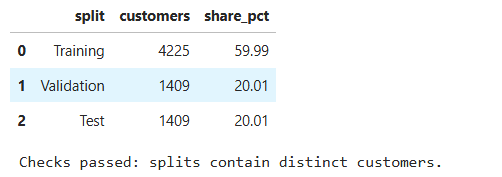

In [9]:
behavior_summary = (
    train_df
    .groupby("Churn")[["tenure", "MonthlyCharges"]]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(behavior_summary)

tenure                      MonthlyCharges                     
       count   mean median    std          count   mean median    std
Churn                                                                
No      3104  37.52   37.0  24.27           3104  61.25  64.38  30.96
Yes     1121  17.82   10.0  19.43           1121  74.54  79.75  24.62

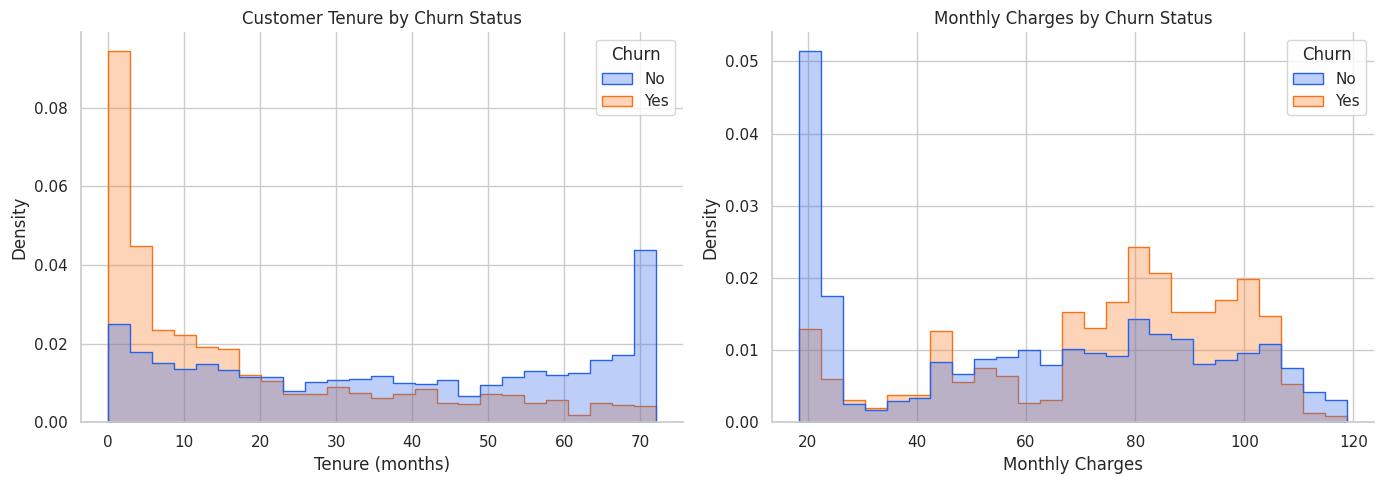

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

features = ["tenure", "MonthlyCharges"]
titles = ["Customer Tenure", "Monthly Charges"]
labels = ["Tenure (months)", "Monthly Charges"]

for ax, feature, title, label in zip(
    axes, features, titles, labels
):
    sns.histplot(
        data = train_df,
        x = feature, 
        hue = "Churn",
        hue_order = ["No", "Yes"],
        bins = 25,
        stat = "density",
        common_norm = False, 
        multiple = "layer",
        element = "step",
        alpha = 0.30,
        palette = {"No": "#2563EB", "Yes": "#F97316"},
        ax = ax,
    )

    ax.set_title(f"{title} by Churn Status")
    ax.set_xlabel(label)
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()
    

### Initial Observations

Within the training sample:

- Customers who churned had a median tenure of 10 months, compared
  with 37 months among customers who stayed.
- Mean monthly charges were 74.54 among churners and 61.25 among
  customers who stayed—a difference of 13.29.
- The mean tenure among churners exceeded their median tenure,
  suggesting an upper tail of longer-tenure customers.

These are unadjusted comparisons. Contract type, service mix and other
characteristics may help explain the differences. We next examine churn
rates within contract categories.

In [11]:
contract_order = ["Month-to-month", "One year", "Two year"]

contract_summary = (
    train_df
    .groupby("Contract", observed=True)
    .agg(
        customers=("ChurnFlag", "size"),
        churned=("ChurnFlag", "sum"),
        churn_rate=("ChurnFlag", "mean"),
    )
    .reindex(contract_order)
)

contract_summary["churn_rate_pct"] = (
    100 * contract_summary["churn_rate"]
)

display(
    contract_summary[
        ["customers", "churned", "churn_rate_pct"]
    ].round(2)
)

,customers,churned,churn_rate_pct
Contract,,,
Month-to-month,2326,1002,43.08
One year,865,93,10.75
Two year,1034,26,2.51


### Contract Type and Churn

Observed churn rates differ substantially across contract categories:
43.08% for month-to-month customers, 10.75% for one-year customers
and 2.51% for two-year customers.

We quantify these differences using:
- **95% Wilson confidence intervals** for each group's churn proportion.
- **A chi-square test of independence** to assess evidence of association.
- **Cramér's V** to describe the strength of that association.

These are exploratory, unadjusted comparisons. Confidence intervals
reflect sampling uncertainty under independent-observation assumptions;
they do not account for bias or establish real-world representativeness.

In [12]:
from statistics import NormalDist
from scipy.stats import chi2_contingency

z = NormalDist().inv_cdf(0.975)

n = contract_summary["customers"].astype(float)
p = contract_summary["churn_rate"].astype(float)

denominator = 1 + z**2 / n

centre = (p + z**2 / (2 * n)) / denominator

half_width = (
    z * np.sqrt(
        p * (1 - p) / n
        + z**2 / (4 * n**2)
    ) / denominator 
)

contract_summary["ci_lower_pct"] = 100 * (centre - half_width)
contract_summary["ci_upper_pct"] = 100 * (centre + half_width)

report_columns = [
    "customers",
    "churned",
    "churn_rate_pct",
    "ci_lower_pct",
    "ci_upper_pct",
]

print(contract_summary[report_columns].round(2).to_string())

contingency = pd.crosstab(
    train_df["Contract"],
    train_df["ChurnFlag"], 
).reindex(
    index = contract_order,
    columns = [0,1],
    fill_value = 0,
)

chi2, p_value, dof, expected = chi2_contingency(
    contingency, 
    correction = False
)

sample_size = contingency.to_numpy().sum()
dimension = min(contingency.shape) - 1

cramers_v = np.sqrt(
    chi2 / sample_size * dimension
)

print(f"\n Chi-square statistic: {chi2:.2f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.3e}")
print(f"Cramer's V: {cramers_v:.3f}")
print(f"Smallest expected cell count: {expected.min():.2f}")

                customers  churned  churn_rate_pct  ci_lower_pct  ci_upper_pct
Contract                                                                      
Month-to-month       2326     1002           43.08         41.08         45.10
One year              865       93           10.75          8.86         12.99
Two year             1034       26            2.51          1.72          3.66

 Chi-square statistic: 743.18
Degrees of freedom: 2
P-value: 4.170e-162
Cramer's V: 0.419
Smallest expected cell count: 229.51


### Interpretation

Contract type is associated with churn in the training sample
(χ² = 743.18, df = 2, p < 0.001; Cramér's V = 0.419).

Month-to-month customers had an observed churn rate of 43.08%
(95% Wilson CI: 41.08%–45.10%), compared with 10.75% for one-year
customers and 2.51% for two-year customers.

These differences identify contract type as a useful characteristic
for further segmentation and predictive modelling. They do not establish
that changing a customer's contract would prevent churn. Tenure,
service mix and customer selection may contribute to the association.

In [13]:
rng = np.random.default_rng(SEED)
n_bootstrap = 3000

comparison_rows = []

for feature in ["tenure", "MonthlyCharges"]:
    stayed = (
        train_df.loc[train_df["ChurnFlag"] == 0, feature]
        .dropna()
        .to_numpy(dtype=float)
    )

    churned = (
        train_df.loc[train_df["ChurnFlag"] == 1, feature]
        .dropna()
        .to_numpy(dtype=float)
    )

    observed_difference = churned.mean() - stayed.mean()

    bootstrap_differences = np.empty(n_bootstrap)

    for i in range(n_bootstrap):
        stayed_sample = rng.choice(
            stayed, size=len(stayed), replace=True
        )

        churned_sample = rng.choice(
            churned, size=len(churned), replace=True
        )

        bootstrap_differences[i] = (
            churned_sample.mean() - stayed_sample.mean()
        )

    lower, upper = np.quantile(
        bootstrap_differences, [0.025, 0.975]
    )

    comparison_rows.append({
        "feature": feature,
        "stayed_mean": stayed.mean(),
        "churned_mean": churned.mean(),
        "mean_difference": observed_difference,
        "ci_lower": lower,
        "ci_upper": upper,
    })

numeric_comparison = pd.DataFrame(comparison_rows)

print(numeric_comparison.round(2).to_string(index=False))

       feature  stayed_mean  churned_mean  mean_difference  ci_lower  ci_upper
        tenure        37.52         17.82           -19.70    -21.13    -18.28
MonthlyCharges        61.25         74.54            13.29     11.49     15.10


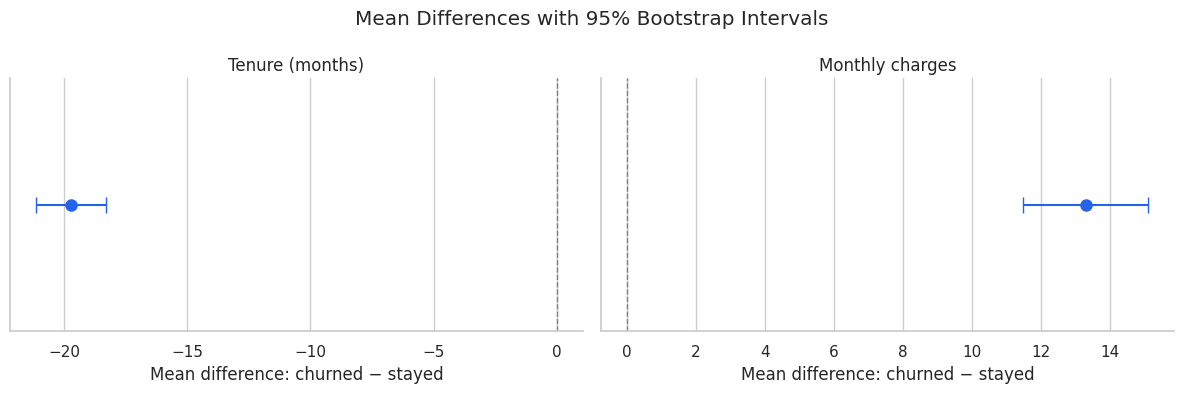

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (_, row) in zip(
    axes, numeric_comparison.iterrows()
):
    difference = row["mean_difference"]

    ax.errorbar(
        x=difference,
        y=0,
        xerr=np.array([
            [difference - row["ci_lower"]],
            [row["ci_upper"] - difference],
        ]),
        fmt="o",
        markersize=8,
        capsize=6,
        color="#2563EB",
    )

    ax.axvline(
        0,
        color="gray",
        linestyle="--",
        linewidth=1,
    )

    titles = {
        "tenure": "Tenure (months)",
        "MonthlyCharges": "Monthly charges",
    }
    ax.set_title(titles[row["feature"]])
    ax.set_xlabel("Mean difference: churned − stayed")
    ax.set_yticks([])

fig.suptitle("Mean Differences with 95% Bootstrap Intervals")
plt.tight_layout()
plt.show()

## 4. Customer Segmentation

Can we identify groups of customers with similar tenure, spending,
contracts and service usage without using churn labels?

We begin with an exploratory K-means baseline using:
- Tenure and monthly charges
- Contract type
- Internet service
- Technical support
- Online security

Numerical features are standardised, while categorical features are
one-hot encoded. Preprocessing is fitted only on training customers.

K-means uses Euclidean distance, so the resulting segments depend on
feature selection, encoding and scaling. We will examine separation,
stability and customer profiles before interpreting the groups.

Churn labels are excluded from cluster formation and cluster-count
selection. They will be used afterward to describe the selected segments.

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

cluster_numeric = [
    "tenure",
    "MonthlyCharges",
]

cluster_categorical = [
    "Contract",
    "InternetService",
    "TechSupport",
    "OnlineSecurity",
]

cluster_features = cluster_numeric + cluster_categorical

cluster_input = train_df[cluster_features].copy()

missing_counts = cluster_input.isna().sum()

if missing_counts.any():
    raise ValueError(
        "Missing clustering inputs require investigation:\n"
        + missing_counts[missing_counts > 0].to_string()
    )

cluster_preprocessor = ColumnTransformer(
    transformers = [
        (
            "numeric",
            StandardScaler(),
            cluster_numeric,
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown = "ignore",
                sparse_output = False, 
                dtype = np.float64,
            ),
            cluster_categorical,
        ),
    ],
    remainder = "drop",
)

X_cluster = cluster_preprocessor.fit_transform(cluster_input)

print(f"Customers: {X_cluster.shape[0]:,}")
print(f"Transformed features: {X_cluster.shape[1]:,}")

print("\n Transformed feature names:")
print(cluster_preprocessor.get_feature_names_out())

assert np.isfinite(X_cluster).all()

print("\n Checks passed: clutering inputs are finite.")

Customers: 4,225
Transformed features: 14

 Transformed feature names:
['numeric__tenure' 'numeric__MonthlyCharges'
 'categorical__Contract_Month-to-month' 'categorical__Contract_One year'
 'categorical__Contract_Two year' 'categorical__InternetService_DSL'
 'categorical__InternetService_Fiber optic'
 'categorical__InternetService_No' 'categorical__TechSupport_No'
 'categorical__TechSupport_No internet service'
 'categorical__TechSupport_Yes' 'categorical__OnlineSecurity_No'
 'categorical__OnlineSecurity_No internet service'
 'categorical__OnlineSecurity_Yes']

 Checks passed: clutering inputs are finite.


,k,inertia,silhouette,smallest_cluster_pct
0,2,13150.098,0.354,21.491
1,3,9242.302,0.352,21.491
2,4,7483.225,0.348,21.491
3,5,6368.162,0.361,15.953
4,6,5525.828,0.368,8.568
5,7,5082.177,0.365,8.663
6,8,4640.126,0.371,8.568


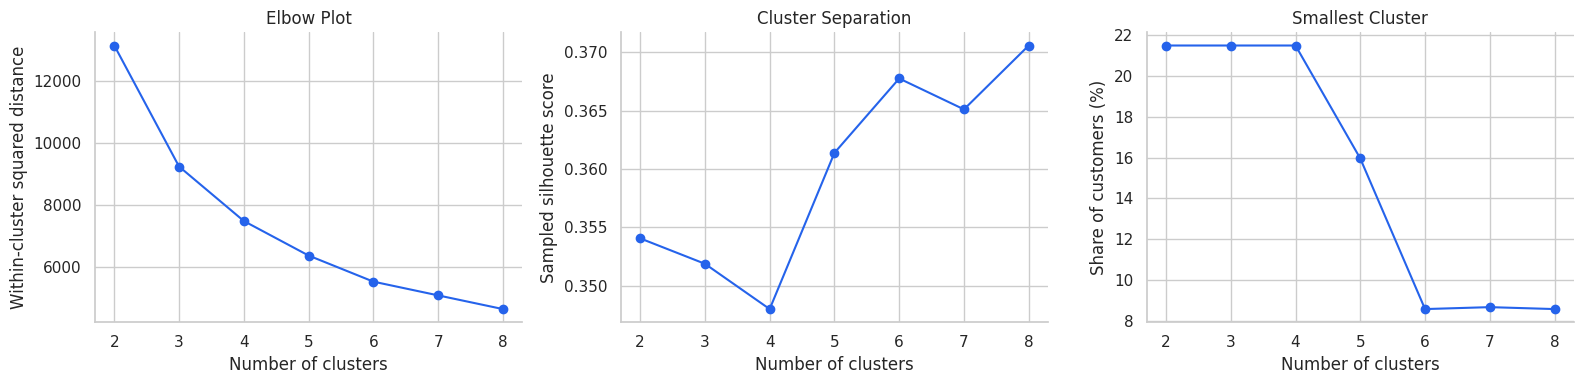

In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_models = {}
cluster_results = []

for k in range(2, 9):
    model = KMeans(
        n_clusters = k,
        n_init = 20,
        random_state = SEED
    )

    labels = model.fit_predict(X_cluster)

    silhouette = silhouette_score(
        X_cluster, 
        labels, 
        sample_size = min(2000, len(X_cluster)),
        random_state = SEED
    )

    sizes = np.bincount(labels, minlength = k)
    cluster_models[k] = model

    cluster_results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette,
        "smallest_cluster_pct": 100 * sizes.min() / len(labels),
    })

cluster_diagnostics = pd.DataFrame(cluster_results)
display(cluster_diagnostics.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

plot_settings = [
    ("inertia", "Elbow Plot", "Within-cluster squared distance"),
    ("silhouette", "Cluster Separation", "Sampled silhouette score"),
    (
        "smallest_cluster_pct",
        "Smallest Cluster",
        "Share of customers (%)",
    ),
]

for ax, (metric, title, ylabel) in zip(axes, plot_settings):
    ax.plot(
        cluster_diagnostics["k"],
        cluster_diagnostics[metric],
        marker="o",
        color="#2563EB",
    )

    ax.set_title(title)
    ax.set_xlabel("Number of clusters")
    ax.set_ylabel(ylabel)
    ax.set_xticks(cluster_diagnostics["k"])

plt.tight_layout()
plt.show()

### Selecting and Checking the Cluster Count

The inertia curve shows diminishing improvements around 3–4 clusters,
without a sharply defined elbow.

We provisionally select **four clusters** as a balance between simplicity
and segmentation detail. Its sampled silhouette score is approximately
0.348, and its smallest cluster contains 21.49% of training customers.

Four clusters do not have the highest silhouette score, so the elbow
alone is insufficient to establish this as the best solution.

We compare 3, 4, 5, 6 and 8 clusters for stability. Each model is refitted
on five random subsets containing 80% of training customers. Its
assignments for all training customers are compared with the corresponding
full-training solution using Adjusted Rand Index (ARI).

ARI accounts for chance agreement and arbitrary cluster label numbering:
- **1:** identical assignments.
- **Near 0:** agreement close to chance.
- **Negative:** agreement below chance.

Preprocessing remains fixed during this check. The results measure
sensitivity to customer subsampling and initialisation, rather than
stability of the complete preprocessing pipeline.

The final choice will consider stability and customer-profile
interpretability. Churn labels are not used to select the cluster count.

Stability across five customer subsamples:
    mean    min    max
k                     
3  0.993  0.986  0.998
4  0.994  0.988  0.997
5  0.997  0.996  0.999
6  0.996  0.992  0.999
8  0.993  0.988  0.996


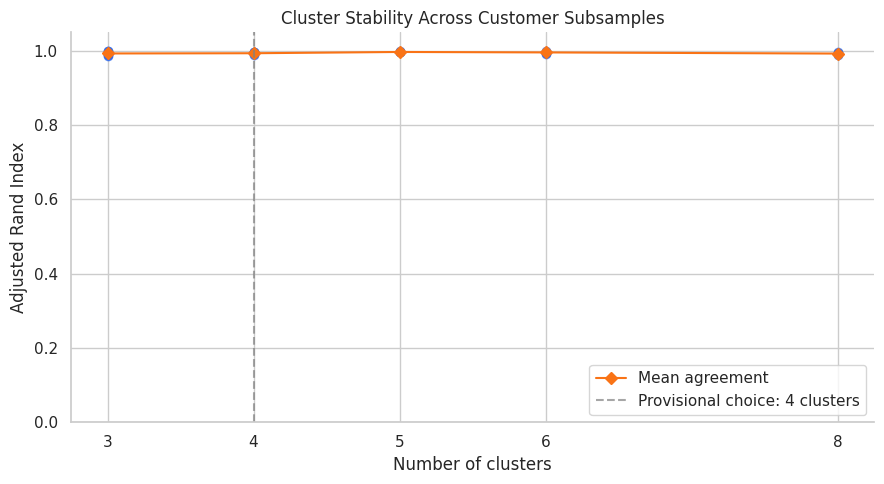


Provisional four-cluster sizes:
Cluster
0    1193
1     908
2    1185
3     939


In [17]:
from sklearn.metrics import adjusted_rand_score

candidate_ks = [3, 4, 5, 6, 8]
selected_k = 4 
stability_rows = []

for k in candidate_ks:
    reference_labels = cluster_models[k].predict(X_cluster)

    for repeat in range(5):
        repeat_seed = SEED + repeat + 1
        sample_rng = np.random.default_rng(repeat_seed)

        subset_indices = sample_rng.choice(
            len(X_cluster),
            size=int(0.80 * len(X_cluster)),
            replace=False,
        )

        subset_model = KMeans(
            n_clusters=k,
            n_init=20,
            random_state=repeat_seed,
        )

        subset_model.fit(X_cluster[subset_indices])

        refit_labels = subset_model.predict(X_cluster)

        stability_rows.append({
            "k": k,
            "repeat": repeat + 1,
            "ari": adjusted_rand_score(
                reference_labels,
                refit_labels,
            ),
        })

stability_results = pd.DataFrame(stability_rows)

stability_summary = (
    stability_results.groupby("k")["ari"]
    .agg(["mean", "min", "max"])
)

print("Stability across five customer subsamples:")
print(stability_summary.round(3).to_string())

selected_cluster_model = cluster_models[selected_k]

cluster_labels = selected_cluster_model.predict(X_cluster)

clustered_train = train_df.copy()
clustered_train["Cluster"] = cluster_labels

fig, ax = plt.subplots(figsize=(9, 5))

for k in candidate_ks:
    scores = stability_results.loc[
        stability_results["k"] == k, "ari"
    ]

    ax.scatter(
        np.repeat(k, len(scores)),
        scores,
        color="#2563EB",
        alpha=0.65,
    )

ax.plot(
    stability_summary.index,
    stability_summary["mean"],
    color="#F97316",
    marker="D",
    label="Mean agreement",
)

ax.axvline(
    selected_k,
    color="gray",
    linestyle="--",
    alpha=0.7,
    label="Provisional choice: 4 clusters",
)

ax.set_xticks(candidate_ks)
ax.set_xlabel("Number of clusters")
ax.set_ylabel("Adjusted Rand Index")
ax.set_title("Cluster Stability Across Customer Subsamples")

ax.set_ylim(
    min(0, stability_results["ari"].min() - 0.05),
    1.05,
)

ax.legend()
plt.tight_layout()
plt.show()

print("\nProvisional four-cluster sizes:")
print(
    clustered_train["Cluster"]
    .value_counts()
    .sort_index()
    .rename("customers")
    .to_string()
)

### Four-Cluster Customer Profiles

The four-cluster solution showed high agreement across five customer
subsamples (mean ARI: 0.994; minimum: 0.988), with preprocessing held fixed.

All four clusters contain substantial numbers of customers. We retain
four clusters for profile inspection, recognising that other tested
cluster counts were also highly stable.

The PCA plot projects the clustering inputs onto two dimensions.
Clustering itself uses all transformed features; apparent separation
or overlap in the projection does not fully describe the original space.

Profile charts show numerical averages and categorical proportions.
Cluster numbers are identifiers, not rankings.

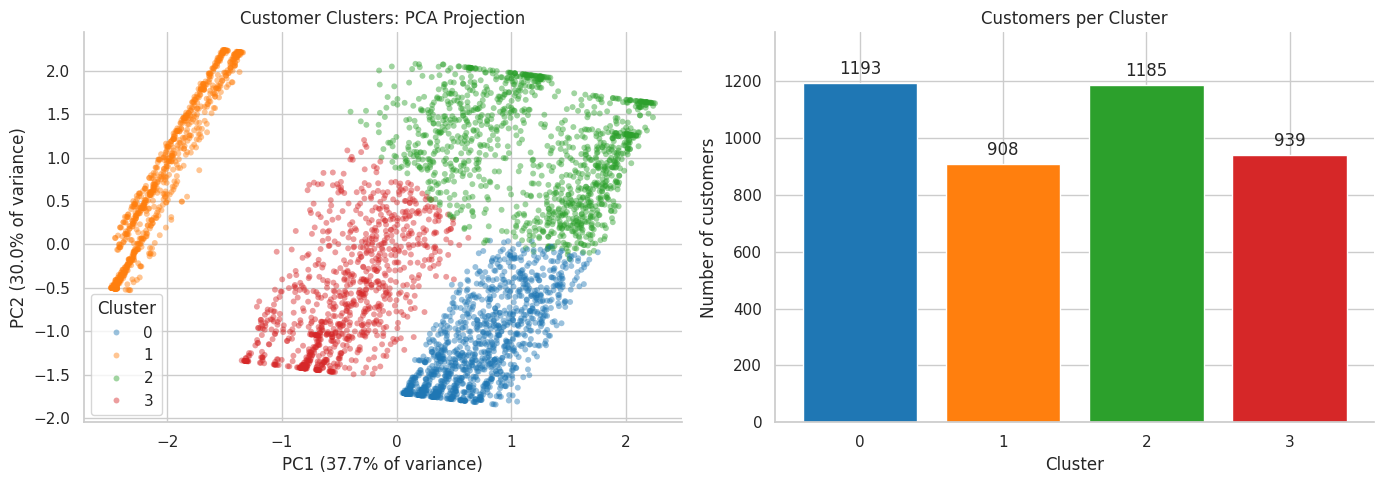

Variance retained by two PCA components: 67.7%


In [18]:
from sklearn.decomposition import PCA

pca = PCA(n_components = 2)
coordinates = pca.fit_transform(X_cluster)

pca_plot = pd.DataFrame({
    "PC1": coordinates[:, 0],
    "PC2": coordinates[:, 1],
    "Cluster": cluster_labels.astype(str),
})

cluster_order = list(range(selected_k))
cluster_names = [str(k) for k in cluster_order]

palette = dict(zip(
    cluster_names,
    sns.color_palette("tab10", n_colors = selected_k),
))

fig, axes = plt.subplots(1, 2, figsize = (14,5))

sns.scatterplot(
    data = pca_plot,
    x = "PC1",
    y = "PC2",
    hue = "Cluster",
    hue_order = cluster_names,
    palette = palette,
    alpha = 0.45,
    s = 18,
    linewidth = 0,
    ax = axes[0],
)

variance = pca.explained_variance_ratio_ * 100


axes[0].set_title("Customer Clusters: PCA Projection")
axes[0].set_xlabel(f"PC1 ({variance[0]:.1f}% of variance)")
axes[0].set_ylabel(f"PC2 ({variance[1]:.1f}% of variance)")

sizes = (
    clustered_train["Cluster"]
    .value_counts()
    .reindex(cluster_order)
)

bars = axes[1].bar(
    cluster_names,
    sizes.to_numpy(),
    color=[palette[name] for name in cluster_names],
)

axes[1].bar_label(bars, padding=4)
axes[1].set_title("Customers per Cluster")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Number of customers")
axes[1].set_ylim(0, sizes.max() * 1.15)

plt.tight_layout()
plt.show()

print(
    f"Variance retained by two PCA components: "
    f"{variance.sum():.1f}%"
)

Mean numerical characteristics:
         tenure  MonthlyCharges
Cluster                        
0         17.78           86.03
1         29.87           21.13
2         60.60           87.61
3         17.36           51.17


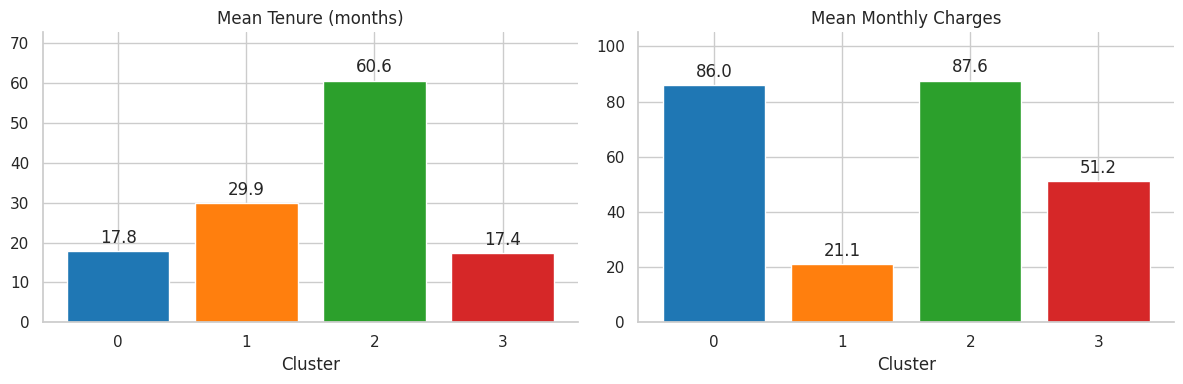

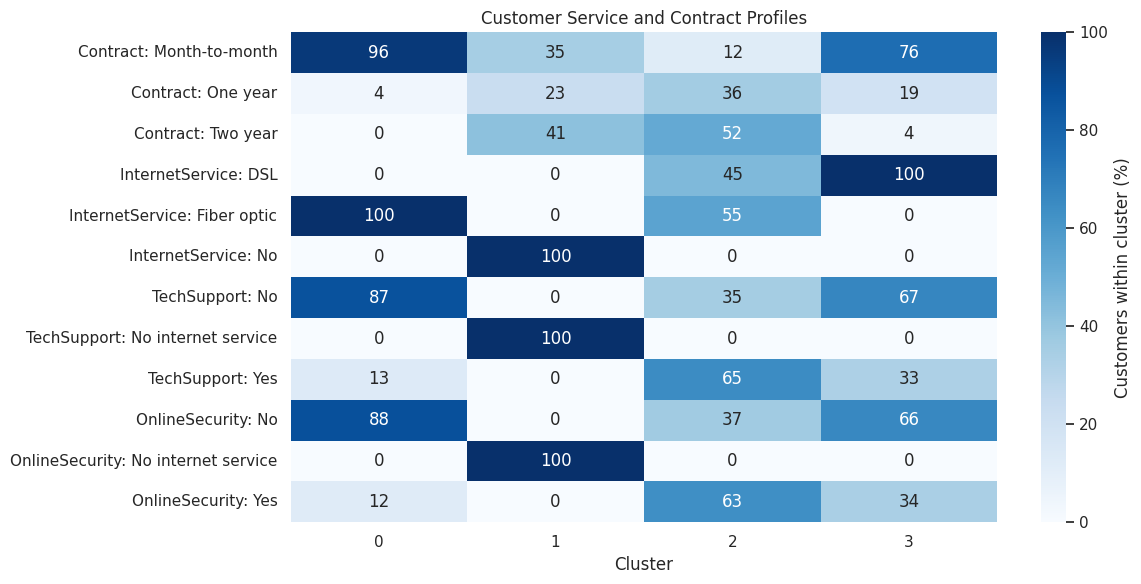

In [19]:
numeric_profiles = (
    clustered_train.groupby("Cluster")[cluster_numeric]
    .mean()
    .reindex(cluster_order)
)

print("Mean numerical characteristics:")
print(numeric_profiles.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, feature, title in zip(
    axes,
    cluster_numeric,
    ["Mean Tenure (months)", "Mean Monthly Charges"],
):
    values = numeric_profiles[feature].to_numpy()

    bars = ax.bar(
        cluster_names,
        values,
        color=[palette[name] for name in cluster_names],
    )

    ax.bar_label(bars, fmt="%.1f", padding=3)
    ax.set_title(title)
    ax.set_xlabel("Cluster")
    ax.set_ylim(0, values.max() * 1.2)

plt.tight_layout()
plt.show()

category_tables = []

for feature in cluster_categorical:
    percentages = pd.crosstab(
        clustered_train["Cluster"],
        clustered_train[feature],
        normalize="index",
    ).reindex(cluster_order) * 100

    percentages.columns = [
        f"{feature}: {category}"
        for category in percentages.columns
    ]

    category_tables.append(percentages)

categorical_profiles = pd.concat(category_tables, axis=1)

fig, ax = plt.subplots(
    figsize=(12, max(6, len(categorical_profiles.columns) * 0.4))
)

sns.heatmap(
    categorical_profiles.T,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Customers within cluster (%)"},
    ax=ax,
)

ax.set_title("Customer Service and Contract Profiles")
ax.set_xlabel("Cluster")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

### Segment Interpretation

The four-cluster solution identifies the following customer profiles:

- **Cluster 0 — Shorter-tenure fibre customers:** High monthly charges,
  predominantly month-to-month contracts, and relatively low uptake of
  technical support and online security.
- **Cluster 1 — Customers without internet service:** Low monthly charges
  and a mixture of contract durations.
- **Cluster 2 — Long-tenure internet customers:** High monthly charges,
  predominantly annual contracts, and greater uptake of support and security.
- **Cluster 3 — Shorter-tenure DSL customers:** Moderate monthly charges
  and predominantly month-to-month contracts.

The first two principal components retain 67.7% of transformed-feature
variance. Their projection supports visual inspection but does not
establish that four is the uniquely correct number of clusters.

Internet-service status is represented in multiple related inputs.
Consequently, segment boundaries partly reflect the chosen encoding
and feature weighting. These groups are exploratory customer profiles,
not independently verified customer types.

         customers  churned  churn_rate_pct  ci_lower_pct  ci_upper_pct
Cluster                                                                
0             1193      681           57.08         54.26         59.86
1              908       66            7.27          5.75          9.14
2             1185      119           10.04          8.46         11.88
3              939      255           27.16         24.41         30.09


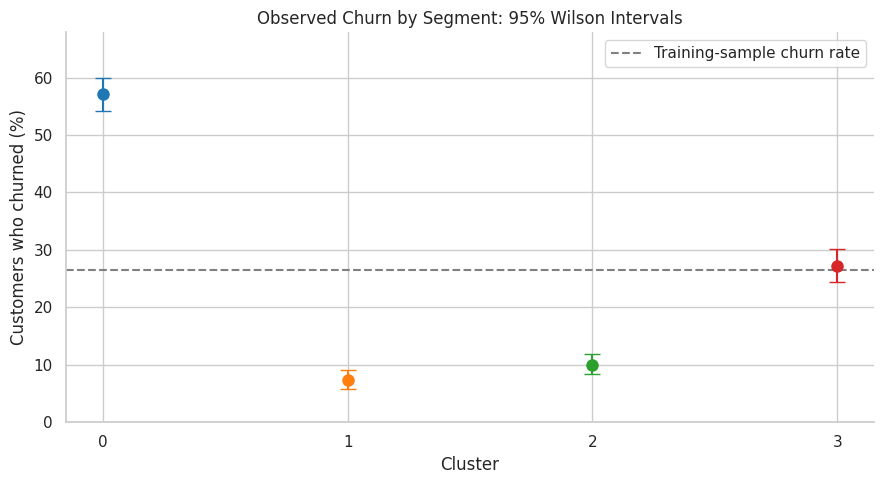

In [20]:
from statistics import NormalDist

segment_churn = (
    clustered_train.groupby("Cluster")
    .agg(
        customers=("ChurnFlag", "size"),
        churned=("ChurnFlag", "sum"),
        churn_rate=("ChurnFlag", "mean"),
    )
    .reindex(cluster_order)
)

z = NormalDist().inv_cdf(0.975)

n = segment_churn["customers"].astype(float)
p = segment_churn["churn_rate"].astype(float)

denominator = 1 + z**2 / n
centre = (p + z**2 / (2 * n)) / denominator

half_width = (
    z * np.sqrt(
        p * (1 - p) / n
        + z**2 / (4 * n**2)
    ) / denominator
)

segment_churn["churn_rate_pct"] = 100 * p
segment_churn["ci_lower_pct"] = 100 * (centre - half_width)
segment_churn["ci_upper_pct"] = 100 * (centre + half_width)

print(
    segment_churn[
        [
            "customers",
            "churned",
            "churn_rate_pct",
            "ci_lower_pct",
            "ci_upper_pct",
        ]
    ].round(2).to_string()
)

rates = segment_churn["churn_rate_pct"]

errors = np.vstack([
    rates - segment_churn["ci_lower_pct"],
    segment_churn["ci_upper_pct"] - rates,
])

fig, ax = plt.subplots(figsize=(9, 5))

for position, cluster in enumerate(cluster_order):
    ax.errorbar(
        x=position,
        y=rates.loc[cluster],
        yerr=errors[:, position:position + 1],
        fmt="o",
        markersize=8,
        capsize=6,
        color=palette[str(cluster)],
    )

ax.axhline(
    100 * clustered_train["ChurnFlag"].mean(),
    color="gray",
    linestyle="--",
    label="Training-sample churn rate",
)

ax.set_xticks(range(selected_k))
ax.set_xticklabels(cluster_names)
ax.set_xlabel("Cluster")
ax.set_ylabel("Customers who churned (%)")
ax.set_title("Observed Churn by Segment: 95% Wilson Intervals")
ax.set_ylim(
    0,
    segment_churn["ci_upper_pct"].max() + 8,
)
ax.legend()

plt.tight_layout()
plt.show()

### Churn Across Customer Segments

Observed churn differs considerably across the four customer segments.

- **Cluster 0:** Shorter-tenure fibre customers have the highest observed
  churn rate at 57.08%. This group contains 28.24% of training customers
  but 60.75% of training churners.
- **Cluster 1:** Customers without internet service have the lowest
  observed churn rate at 7.27%.
- **Cluster 2:** Long-tenure internet customers have a churn rate of
  10.04%, despite monthly charges similar to Cluster 0.
- **Cluster 3:** Shorter-tenure DSL customers have a churn rate of 27.16%,
  close to the overall training-sample rate of 26.53%.

The contrast between Clusters 0 and 2 illustrates why monthly charges
alone provide an incomplete picture: tenure, contracts and service
characteristics also differ substantially.

These rates describe the fitted training segments. They do not establish
causal effects, individual churn probabilities or the effectiveness of
retention interventions. Wilson intervals do not incorporate uncertainty
from learning the clusters.

## 5. Predictive Modelling

Customer segmentation describes broad groups. Predictive modelling
evaluates whether customer characteristics can rank individual churn risk.

We begin with a dummy baseline and logistic regression, followed by
CatBoost. Preprocessing will be fitted within each training fold.

Customer identifiers, the original churn label and its encoded copy are
excluded from predictors. Cluster assignments are also excluded from
the initial models, keeping the predictive comparison separate from
the exploratory segmentation.

Training cross-validation supports development. Validation data supports
model selection, and test data remains reserved for final evaluation.

In [21]:
excluded_columns = {
    "customerID",
    "Churn",
    "ChurnFlag",
    "Cluster",
}

model_features = [
    column for column in train_df.columns
    if column not in excluded_columns
]

model_numeric = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
]

model_categorical = [
    column for column in model_features
    if column not in model_numeric
]

X_train = train_df[model_features].copy()
y_train = train_df["ChurnFlag"].copy()

X_valid = valid_df[model_features].copy()
y_valid = valid_df["ChurnFlag"].copy()

for frame in [X_train, X_valid]:
    for column in model_categorical:
        frame[column] = (
            frame[column]
            .astype(object)
            .where(frame[column].notna(), np.nan)
        )

print(f"Training inputs: {X_train.shape}")
print(f"Validation inputs: {X_valid.shape}")
print("\nNumerical predictors:", model_numeric)
print("\nCategorical predictors:", model_categorical)

assert not excluded_columns.intersection(X_train.columns)
assert X_train.columns.equals(X_valid.columns)

print("\nChecks passed: target and identifier columns excluded.")

Training inputs: (4225, 19)
Validation inputs: (1409, 19)

Numerical predictors: ['tenure', 'MonthlyCharges', 'TotalCharges']

Categorical predictors: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Checks passed: target and identifier columns excluded.


### Churn Classification: Benchmarks

We first compare two approaches:

- **Prevalence benchmark:** Predicts the training-fold churn proportion
  for every customer.
- **Logistic regression:** Uses customer characteristics to estimate
  individual churn probabilities.

Five-fold stratified cross-validation is performed within the training
set. Imputation, scaling and encoding are fitted separately inside each
fold to prevent preprocessing leakage.

We evaluate:
- **ROC AUC:** Overall ranking discrimination; higher is better.
- **Average precision:** Precision–recall performance; higher is better.
- **Log loss:** Probability quality; lower is better.
- **Brier score:** Squared probability error; lower is better.

Log loss and Brier score measure overall probability quality, not
calibration alone. Validation and test data remain unused at this stage.

In [22]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        ),
    ),
])

model_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, model_numeric),
        ("categorical", categorical_pipeline, model_categorical),
    ],
    remainder="drop",
)

baseline_models = {
    "Prevalence benchmark": DummyClassifier(strategy="prior"),

    "Logistic regression": Pipeline([
        ("preprocessor", clone(model_preprocessor)),
        (
            "model",
            LogisticRegression(
                C=1.0,
                max_iter=2000,
                solver="lbfgs",
            ),
        ),
    ]),
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)

cv_splits = list(cv.split(X_train, y_train))

print("Models ready:", list(baseline_models))
print(f"Cross-validation folds: {len(cv_splits)}")

Models ready: ['Prevalence benchmark', 'Logistic regression']
Cross-validation folds: 5


In [23]:
scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "log_loss": "neg_log_loss",
    "brier": "neg_brier_score",
}

cv_rows = []

for model_name, estimator in baseline_models.items():
    print(f"Evaluating: {model_name}")

    scores = cross_validate(
        estimator,
        X_train,
        y_train,
        cv=cv_splits,
        scoring=scoring,
        n_jobs=1,
        error_score="raise",
    )

    for fold in range(len(cv_splits)):
        cv_rows.append({
            "model": model_name,
            "fold": fold + 1,
            "roc_auc": scores["test_roc_auc"][fold],
            "average_precision": (
                scores["test_average_precision"][fold]
            ),
            "log_loss": -scores["test_log_loss"][fold],
            "brier": -scores["test_brier"][fold],
        })

baseline_cv_results = pd.DataFrame(cv_rows)

metric_names = [
    "roc_auc",
    "average_precision",
    "log_loss",
    "brier",
]

baseline_cv_summary = (
    baseline_cv_results
    .groupby("model", sort=False)[metric_names]
    .agg(["mean", "std"])
)

print("\nCross-validation means and standard deviations:")
print(baseline_cv_summary.round(4).to_string())

Evaluating: Prevalence benchmark
Evaluating: Logistic regression

Cross-validation means and standard deviations:
                     roc_auc         average_precision         log_loss           brier        
                        mean     std              mean     std     mean     std    mean     std
model                                                                                          
Prevalence benchmark  0.5000  0.0000            0.2653  0.0005   0.5786  0.0005  0.1949  0.0002
Logistic regression   0.8481  0.0119            0.6665  0.0277   0.4143  0.0152  0.1346  0.0043


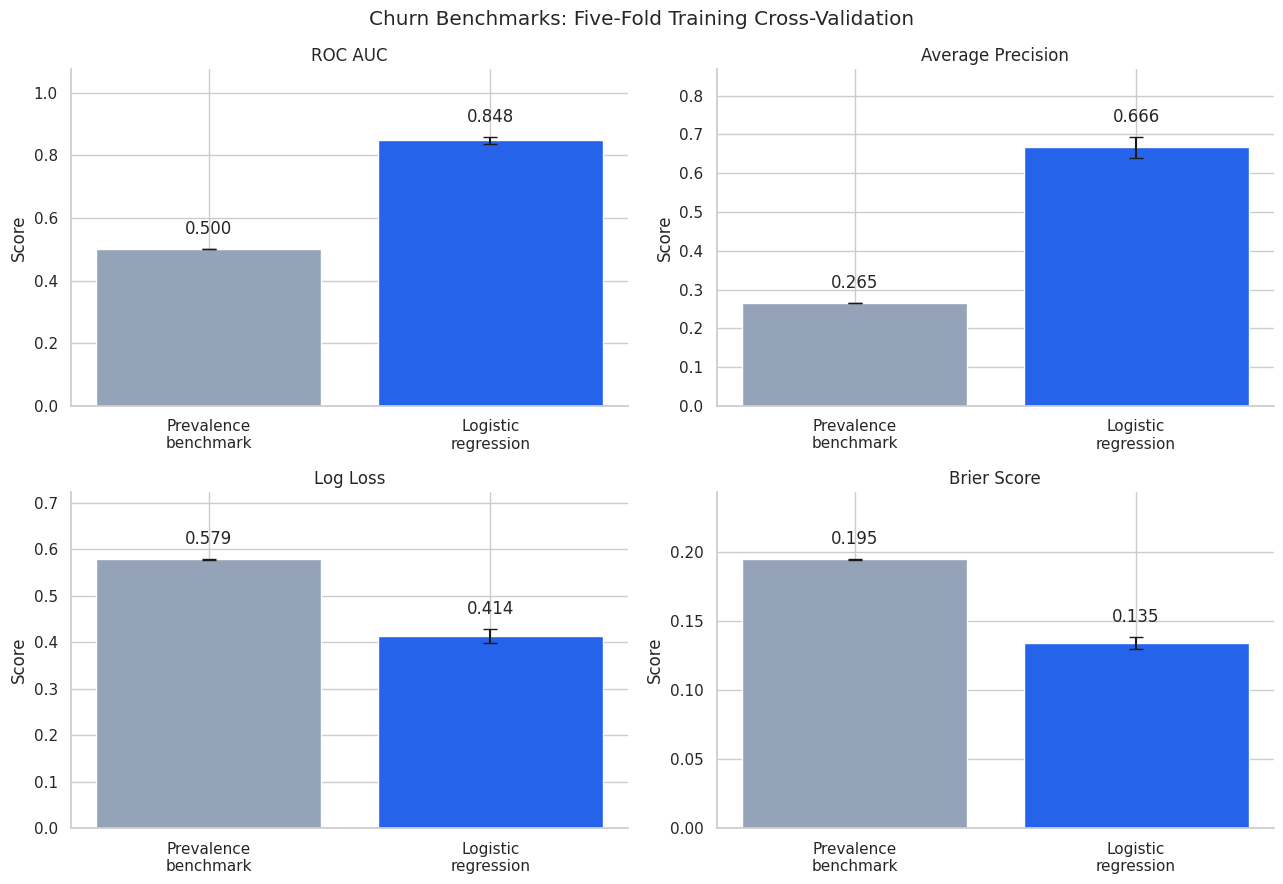

In [24]:
model_order = list(baseline_models)

plot_titles = {
    "roc_auc": "ROC AUC",
    "average_precision": "Average Precision",
    "log_loss": "Log Loss",
    "brier": "Brier Score",
}

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, metric in zip(axes.flat, metric_names):
    summary = (
        baseline_cv_results.groupby("model")[metric]
        .agg(["mean", "std"])
        .reindex(model_order)
    )

    positions = np.arange(len(model_order))

    bars = ax.bar(
        positions,
        summary["mean"].to_numpy(),
        yerr=summary["std"].to_numpy(),
        capsize=5,
        color=["#94A3B8", "#2563EB"],
    )

    ax.bar_label(bars, fmt="%.3f", padding=8)
    ax.set_xticks(positions)
    ax.set_xticklabels(
        ["Prevalence\nbenchmark", "Logistic\nregression"]
    )

    ax.set_title(plot_titles[metric])
    ax.set_ylabel("Score")

    upper_limit = (
        summary["mean"] + summary["std"]
    ).max() * 1.25

    ax.set_ylim(0, upper_limit)

fig.suptitle(
    "Churn Benchmarks: Five-Fold Training Cross-Validation"
)

plt.tight_layout()
plt.show()

### CatBoost: Nonlinear Churn Modelling

Logistic regression achieved a mean cross-validation ROC AUC of 0.8481
and average precision of 0.6665, improving on the prevalence benchmark.

We next evaluate CatBoost, a gradient-boosted tree model that can capture
nonlinear relationships and interactions while handling categorical
features directly.

The initial CatBoost configuration is fixed before evaluation and uses
the same five training folds as the benchmarks. No external validation
or test data is used, and early stopping is not applied.

Categorical values are converted to strings with a fixed missing-value
marker. Numerical missing values are retained for CatBoost to handle.

This comparison evaluates an initial configuration; hyperparameter
selection will follow separately.

In [25]:
from catboost import CatBoostClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
)


X_train_cat = X_train.copy()

for column in model_categorical:
    X_train_cat[column] = (
        X_train_cat[column]
        .astype("string")
        .fillna("__MISSING__")
        .astype(str)
    )

catboost_initial_params = {
    "iterations": 500,
    "depth": 5,
    "learning_rate": 0.04,
    "l2_leaf_reg": 3.0,
    "loss_function": "Logloss",
    "random_seed": SEED,
    "thread_count": 2,
    "verbose": False,
    "allow_writing_files": False,
}

print("CatBoost inputs ready.")
print(f"Shape: {X_train_cat.shape}")

CatBoost inputs ready.
Shape: (4225, 19)


In [26]:
catboost_cv_rows = []

catboost_oof = np.full(len(X_train_cat), np.nan)

for fold, (fit_indices, holdout_indices) in enumerate(
    cv_splits,
    start=1,
):
    model = CatBoostClassifier(**catboost_initial_params)

    model.fit(
        X_train_cat.iloc[fit_indices],
        y_train.iloc[fit_indices],
        cat_features=model_categorical,
    )

    probabilities = model.predict_proba(
        X_train_cat.iloc[holdout_indices]
    )[:, 1]

    actual = y_train.iloc[holdout_indices]

    catboost_oof[holdout_indices] = probabilities

    catboost_cv_rows.append({
        "model": "CatBoost initial",
        "fold": fold,
        "roc_auc": roc_auc_score(actual, probabilities),
        "average_precision": average_precision_score(
            actual, probabilities
        ),
        "log_loss": log_loss(actual, probabilities),
        "brier": brier_score_loss(actual, probabilities),
    })

    print(f"Fold {fold} complete.")

assert np.isfinite(catboost_oof).all()

catboost_cv_results = pd.DataFrame(catboost_cv_rows)

classification_cv_results = pd.concat(
    [baseline_cv_results, catboost_cv_results],
    ignore_index=True,
)

classification_cv_summary = (
    classification_cv_results
    .groupby("model", sort=False)[metric_names]
    .agg(["mean", "std"])
)

print("\nCross-validation comparison:")
print(classification_cv_summary.round(4).to_string())

Fold 1 complete.
Fold 2 complete.
Fold 3 complete.
Fold 4 complete.
Fold 5 complete.

Cross-validation comparison:
                     roc_auc         average_precision         log_loss           brier        
                        mean     std              mean     std     mean     std    mean     std
model                                                                                          
Prevalence benchmark  0.5000  0.0000            0.2653  0.0005   0.5786  0.0005  0.1949  0.0002
Logistic regression   0.8481  0.0119            0.6665  0.0277   0.4143  0.0152  0.1346  0.0043
CatBoost initial      0.8471  0.0099            0.6690  0.0184   0.4149  0.0130  0.1350  0.0039


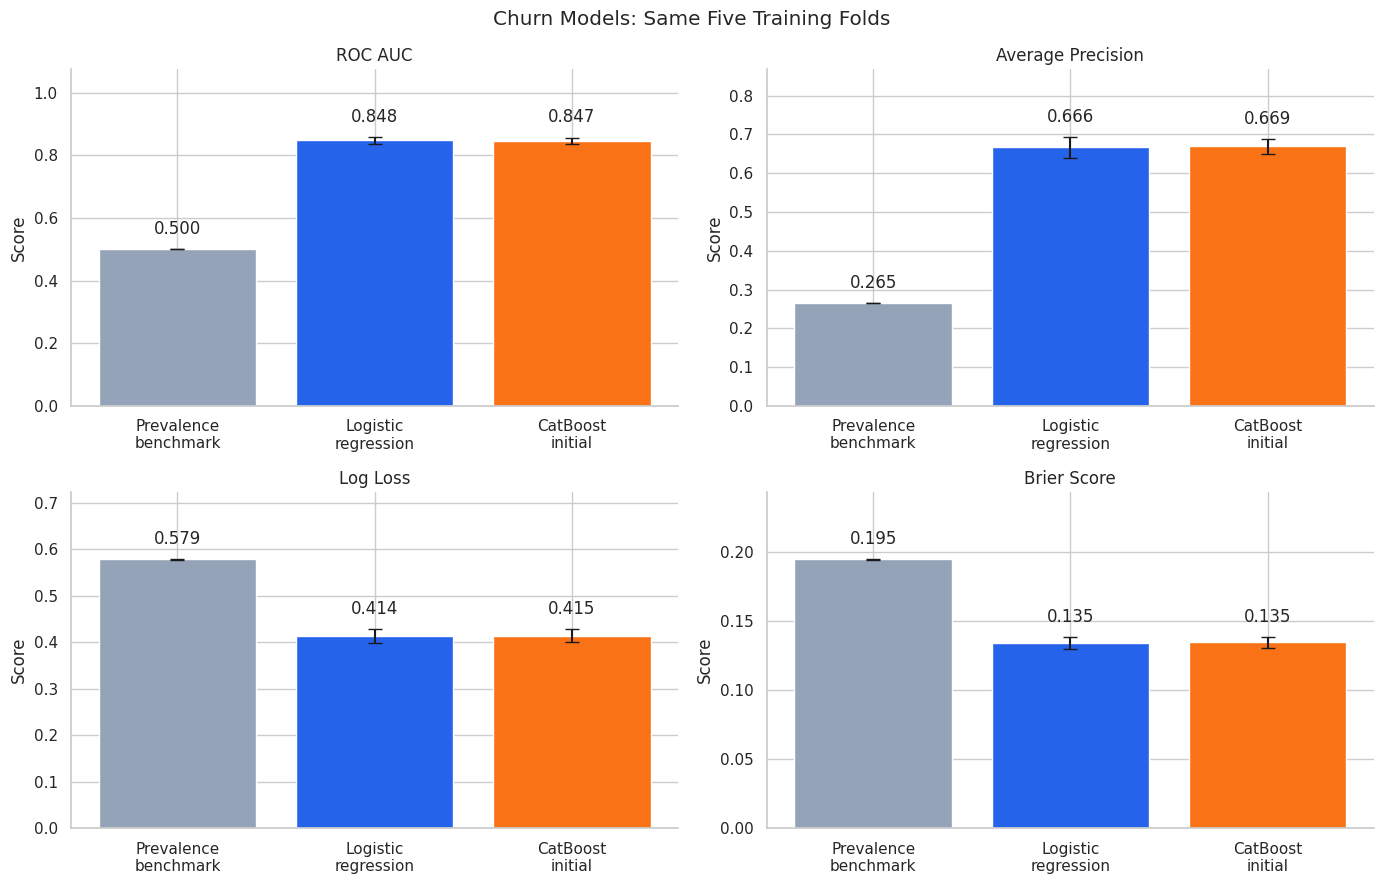

In [27]:
comparison_order = [
    "Prevalence benchmark",
    "Logistic regression",
    "CatBoost initial",
]

display_names = [
    "Prevalence\nbenchmark",
    "Logistic\nregression",
    "CatBoost\ninitial",
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, metric in zip(axes.flat, metric_names):
    summary = (
        classification_cv_results.groupby("model")[metric]
        .agg(["mean", "std"])
        .reindex(comparison_order)
    )

    positions = np.arange(len(comparison_order))

    bars = ax.bar(
        positions,
        summary["mean"].to_numpy(),
        yerr=summary["std"].to_numpy(),
        capsize=5,
        color=["#94A3B8", "#2563EB", "#F97316"],
    )

    ax.bar_label(bars, fmt="%.3f", padding=8)
    ax.set_xticks(positions)
    ax.set_xticklabels(display_names)
    ax.set_title(plot_titles[metric])
    ax.set_ylabel("Score")

    ax.set_ylim(
        0,
        (summary["mean"] + summary["std"]).max() * 1.25,
    )

fig.suptitle(
    "Churn Models: Same Five Training Folds"
)

plt.tight_layout()
plt.show()

### CatBoost Hyperparameter Selection

Initial CatBoost performance is close to logistic regression, with no
clear overall advantage.

We evaluate a small, predefined set of configurations using the same
five training folds. Mean cross-validation log loss is the selection
criterion because probability quality matters for customer prioritization.

The search varies tree depth, regularisation and boosting iterations.
The initial configuration remains a candidate.

Scores used to choose a configuration are development results and may
be optimistic after selection. The selected model will subsequently
be assessed on validation data; test data remains untouched.

In [28]:
search_configs = [
    {
        "name": "Initial",
        "iterations": 500,
        "depth": 5,
        "learning_rate": 0.04,
        "l2_leaf_reg": 3.0,
    },
    {
        "name": "Shallow",
        "iterations": 500,
        "depth": 3,
        "learning_rate": 0.04,
        "l2_leaf_reg": 3.0,
    },
    {
        "name": "More regularisation",
        "iterations": 500,
        "depth": 5,
        "learning_rate": 0.04,
        "l2_leaf_reg": 10.0,
    },
    {
        "name": "Shallow and regularised",
        "iterations": 700,
        "depth": 3,
        "learning_rate": 0.03,
        "l2_leaf_reg": 10.0,
    },
    {
        "name": "Deeper and regularised",
        "iterations": 500,
        "depth": 6,
        "learning_rate": 0.04,
        "l2_leaf_reg": 10.0,
    },
]

search_rows = []

for config in search_configs:
    name = config["name"]

    if name == "Initial":
        for _, row in catboost_cv_results.iterrows():
            search_rows.append({
                "configuration": name,
                "fold": int(row["fold"]),
                "log_loss": row["log_loss"],
            })

        print("Initial: reused existing fold scores.")
        continue

    parameters = {
        **catboost_initial_params,
        **{
            key: value
            for key, value in config.items()
            if key != "name"
        },
    }

    for fold, (fit_indices, holdout_indices) in enumerate(
        cv_splits, start=1
    ):
        candidate = CatBoostClassifier(**parameters)

        candidate.fit(
            X_train_cat.iloc[fit_indices],
            y_train.iloc[fit_indices],
            cat_features=model_categorical,
        )

        probabilities = candidate.predict_proba(
            X_train_cat.iloc[holdout_indices]
        )[:, 1]

        search_rows.append({
            "configuration": name,
            "fold": fold,
            "log_loss": log_loss(
                y_train.iloc[holdout_indices],
                probabilities,
            ),
        })

    print(f"{name}: complete.")

catboost_search_results = pd.DataFrame(search_rows)

search_summary = (
    catboost_search_results
    .groupby("configuration")["log_loss"]
    .agg(["mean", "std"])
    .sort_values("mean")
)

best_config_name = search_summary.index[0]

best_config = next(
    config for config in search_configs
    if config["name"] == best_config_name
)

best_catboost_params = {
    **catboost_initial_params,
    **{
        key: value
        for key, value in best_config.items()
        if key != "name"
    },
}

print("\nSearch results:")
print(search_summary.round(5).to_string())

print(f"\nSelected configuration: {best_config_name}")

Initial: reused existing fold scores.
Shallow: complete.
More regularisation: complete.
Shallow and regularised: complete.
Deeper and regularised: complete.

Search results:
                            mean      std
configuration                            
Shallow                  0.40981  0.01284
Shallow and regularised  0.41017  0.01374
More regularisation      0.41243  0.01220
Deeper and regularised   0.41266  0.01280
Initial                  0.41486  0.01297

Selected configuration: Shallow


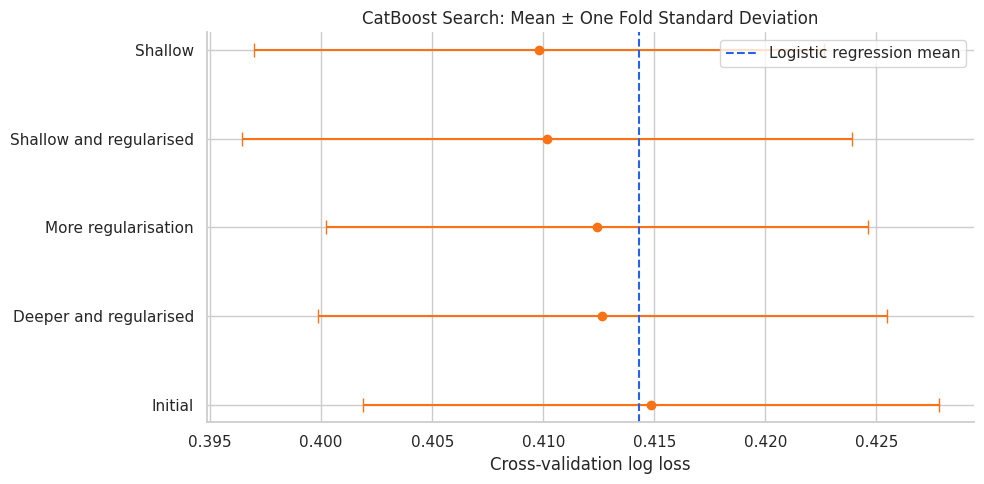

In [29]:
fig, ax = plt.subplots(figsize=(10, 5))

positions = np.arange(len(search_summary))

ax.errorbar(
    search_summary["mean"].to_numpy(),
    positions,
    xerr=search_summary["std"].to_numpy(),
    fmt="o",
    capsize=5,
    color="#F97316",
)

lr_log_loss = baseline_cv_results.loc[
    baseline_cv_results["model"] == "Logistic regression",
    "log_loss",
].mean()

ax.axvline(
    lr_log_loss,
    color="#2563EB",
    linestyle="--",
    label="Logistic regression mean",
)

ax.set_yticks(positions)
ax.set_yticklabels(search_summary.index)
ax.invert_yaxis()

ax.set_xlabel("Cross-validation log loss")
ax.set_title("CatBoost Search: Mean ± One Fold Standard Deviation")
ax.legend()

plt.tight_layout()
plt.show()

## 6. Validation of the Selected Models

The shallow CatBoost configuration achieved the lowest mean
cross-validation log loss among the five candidates (0.40981).

Its parameters are:
- Tree depth: 3
- Boosting iterations: 500
- Learning rate: 0.04
- L2 leaf regularisation: 3.0

We now fit logistic regression and the selected CatBoost configuration
on the complete training set and evaluate their predictions on the
validation set.

ROC and precision–recall curves assess ranking performance. A reliability
diagram compares predicted probabilities with observed churn proportions.

Validation results support model selection. They are not the final
test-set performance estimate.

In [30]:
X_valid_cat = X_valid.copy()

for column in model_categorical:
    X_valid_cat[column] = (
        X_valid_cat[column]
        .astype("string")
        .fillna("__MISSING__")
        .astype(str)
    )

fitted_logistic = clone(
    baseline_models["Logistic regression"]
)

fitted_logistic.fit(X_train, y_train)

fitted_catboost = CatBoostClassifier(**best_catboost_params)

fitted_catboost.fit(
    X_train_cat,
    y_train,
    cat_features=model_categorical,
)

validation_predictions = {
    "Logistic regression": fitted_logistic.predict_proba(
        X_valid
    )[:, 1],

    "Selected CatBoost": fitted_catboost.predict_proba(
        X_valid_cat
    )[:, 1],
}

validation_rows = []

for name, probabilities in validation_predictions.items():
    validation_rows.append({
        "model": name,
        "roc_auc": roc_auc_score(y_valid, probabilities),
        "average_precision": average_precision_score(
            y_valid, probabilities
        ),
        "log_loss": log_loss(y_valid, probabilities),
        "brier": brier_score_loss(y_valid, probabilities),
    })

validation_results = (
    pd.DataFrame(validation_rows)
    .set_index("model")
)

print("Validation results:")
print(validation_results.round(4).to_string())

Validation results:
                     roc_auc  average_precision  log_loss   brier
model                                                            
Logistic regression   0.8360             0.6424    0.4286  0.1381
Selected CatBoost     0.8411             0.6538    0.4215  0.1362


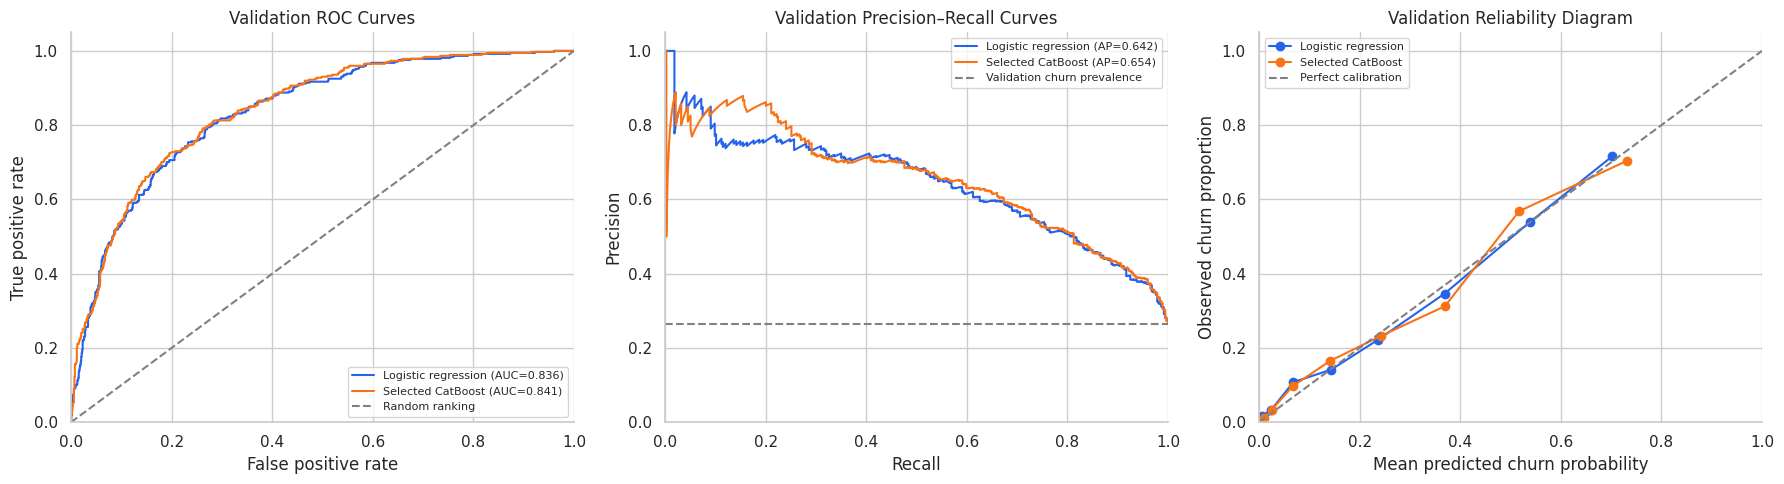

In [31]:
from sklearn.metrics import roc_curve, precision_recall_curve
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

model_colors = {
    "Logistic regression": "#2563EB",
    "Selected CatBoost": "#F97316",
}

for name, probabilities in validation_predictions.items():
    color = model_colors[name]

    fpr, tpr, _ = roc_curve(y_valid, probabilities)

    axes[0].plot(
        fpr,
        tpr,
        color=color,
        label=(
            f"{name} "
            f"(AUC={validation_results.loc[name, 'roc_auc']:.3f})"
        ),
    )

    precision, recall, _ = precision_recall_curve(
        y_valid, probabilities
    )

    axes[1].plot(
        recall,
        precision,
        color=color,
        label=(
            f"{name} "
            f"(AP={validation_results.loc[name, 'average_precision']:.3f})"
        ),
    )

    observed, predicted = calibration_curve(
        y_valid,
        probabilities,
        n_bins=8,
        strategy="quantile",
    )

    axes[2].plot(
        predicted,
        observed,
        marker="o",
        color=color,
        label=name,
    )

axes[0].plot(
    [0, 1], [0, 1],
    linestyle="--", color="gray",
    label="Random ranking",
)

axes[1].axhline(
    y_valid.mean(),
    linestyle="--", color="gray",
    label="Validation churn prevalence",
)

axes[2].plot(
    [0, 1], [0, 1],
    linestyle="--", color="gray",
    label="Perfect calibration",
)

titles = [
    "Validation ROC Curves",
    "Validation Precision–Recall Curves",
    "Validation Reliability Diagram",
]

x_labels = [
    "False positive rate",
    "Recall",
    "Mean predicted churn probability",
]

y_labels = [
    "True positive rate",
    "Precision",
    "Observed churn proportion",
]

for ax, title, xlabel, ylabel in zip(
    axes, titles, x_labels, y_labels
):
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

### Validation Findings

Selected CatBoost achieved a validation ROC AUC of approximately 0.841
and average precision of 0.654, compared with 0.836 and 0.642 for
logistic regression.

This represents a modest ranking improvement on this validation split.
It does not establish a statistically significant advantage.

Both reliability curves broadly follow the ideal diagonal, although
individual bins show deviations. Probability quality will also be
assessed using log loss and Brier score before deciding whether
additional calibration is useful.

## 7. Probability Calibration

Selected CatBoost outperformed logistic regression on all four validation
metrics, including log loss (0.42154 versus 0.42861).

We next evaluate sigmoid calibration, which learns a mapping from
CatBoost's raw scores to churn probabilities.

The mapping is fitted using out-of-fold training scores: each customer's
score is generated by a model that did not train on that customer.
Validation labels are not used to fit the mapping.

The calibrated probabilities are compared with the original probabilities
on validation data. Calibration will be retained only if supported by
the results, with log loss as the primary selection criterion.

Because hyperparameters were selected using training cross-validation,
the out-of-fold scores remain development data rather than an unbiased
final performance estimate. Test data remains untouched.

In [32]:
selected_oof_raw = np.full(len(X_train_cat), np.nan)

for fold, (fit_indices, holdout_indices) in enumerate(
    cv_splits, start=1
):
    fold_model = CatBoostClassifier(**best_catboost_params)

    fold_model.fit(
        X_train_cat.iloc[fit_indices],
        y_train.iloc[fit_indices],
        cat_features=model_categorical,
    )

    selected_oof_raw[holdout_indices] = fold_model.predict(
        X_train_cat.iloc[holdout_indices],
        prediction_type="RawFormulaVal",
    )

    print(f"Calibration scores: fold {fold} complete.")

assert np.isfinite(selected_oof_raw).all()

sigmoid_calibrator = LogisticRegression(
    C=1e6,
    solver="lbfgs",
    max_iter=2000,
)

sigmoid_calibrator.fit(
    selected_oof_raw.reshape(-1, 1),
    y_train,
)

valid_raw_scores = fitted_catboost.predict(
    X_valid_cat,
    prediction_type="RawFormulaVal",
)

valid_calibrated_probabilities = (
    sigmoid_calibrator.predict_proba(
        np.asarray(valid_raw_scores).reshape(-1, 1)
    )[:, 1]
)

calibration_predictions = {
    "CatBoost original": validation_predictions["Selected CatBoost"],
    "CatBoost sigmoid": valid_calibrated_probabilities,
}

print(
    "\nSigmoid slope:",
    round(float(sigmoid_calibrator.coef_[0, 0]), 4),
)

Calibration scores: fold 1 complete.
Calibration scores: fold 2 complete.
Calibration scores: fold 3 complete.
Calibration scores: fold 4 complete.
Calibration scores: fold 5 complete.

Sigmoid slope: 0.9558


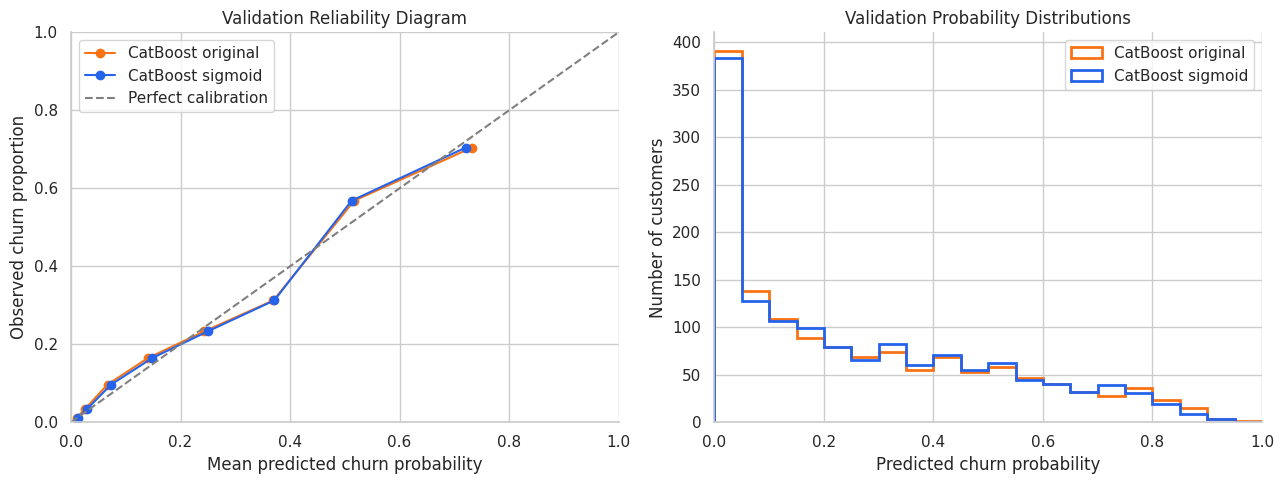

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

calibration_colors = {
    "CatBoost original": "#F97316",
    "CatBoost sigmoid": "#2563EB",
}

for name, probabilities in calibration_predictions.items():
    observed, predicted = calibration_curve(
        y_valid,
        probabilities,
        n_bins=8,
        strategy="quantile",
    )

    axes[0].plot(
        predicted,
        observed,
        marker="o",
        label=name,
        color=calibration_colors[name],
    )

    axes[1].hist(
        probabilities,
        bins=np.linspace(0, 1, 21),
        histtype="step",
        linewidth=2,
        label=name,
        color=calibration_colors[name],
    )

axes[0].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect calibration",
)

axes[0].set_title("Validation Reliability Diagram")
axes[0].set_xlabel("Mean predicted churn probability")
axes[0].set_ylabel("Observed churn proportion")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)

axes[1].set_title("Validation Probability Distributions")
axes[1].set_xlabel("Predicted churn probability")
axes[1].set_ylabel("Number of customers")
axes[1].set_xlim(0, 1)

for ax in axes:
    ax.legend()

plt.tight_layout()
plt.show()

## 8. Calibration Assessment and Probability Model Selection

The reliability diagrams suggest that sigmoid calibration produces only small changes to the original CatBoost probabilities. We therefore compare both versions using numerical metrics.

- **Log loss:** evaluates probability quality while strongly penalizing confident incorrect predictions.
- **Brier score:** measures the mean squared difference between predicted probabilities and observed outcomes.
- **ROC AUC:** evaluates how well the model ranks customers by churn risk.
- **Average precision:** summarizes precision across recall levels.

Lower log loss and Brier score are better; higher ROC AUC and average precision are better.

We use validation log loss as the primary selection criterion and Brier score as the tie-breaker. The test set remains reserved for the final evaluation.

In [34]:
from sklearn.metrics import (
    log_loss,
    brier_score_loss,
    roc_auc_score,
    average_precision_score,
)

calibration_rows = []

for name, probabilities in calibration_predictions.items():
    probabilities = np.asarray(probabilities, dtype=float).ravel()

    if len(probabilities) != len(y_valid):
        raise ValueError(f"{name}: prediction and target lengths differ.")

    if (
        not np.isfinite(probabilities).all()
        or ((probabilities < 0) | (probabilities > 1)).any()
    ):
        raise ValueError(f"{name}: probabilities must be finite and within [0, 1].")

    calibration_rows.append({
        "Model": name,
        "Log loss": log_loss(y_valid, probabilities, labels=[0, 1]),
        "Brier score": brier_score_loss(y_valid, probabilities),
        "ROC AUC": roc_auc_score(y_valid, probabilities),
        "Average precision": average_precision_score(
            y_valid, probabilities
        ),
    })

calibration_results = (
    pd.DataFrame(calibration_rows)
    .set_index("Model")
    .sort_values(["Log loss", "Brier score"], kind="stable")
)

display(calibration_results.style.format("{:.5f}"))

selected_probability_name = calibration_results.index[0]
selected_valid_probabilities = np.asarray(
    calibration_predictions[selected_probability_name],
    dtype=float,
).ravel()

print(f"Selected probability model: {selected_probability_name}")

,Log loss,Brier score,ROC AUC,Average precision
Model,,,,
CatBoost sigmoid,0.42126,0.13625,0.84111,0.65378
CatBoost original,0.42154,0.13620,0.84111,0.65378


Selected probability model: CatBoost sigmoid


## 9. Customer Prioritization: Gains and Lift

A retention team may have capacity to contact only a fraction of customers. We therefore assess whether the model concentrates actual churners near the top of its risk ranking.

Customers are ranked by their predicted churn probability. At each contact capacity, we report:

- **Precision:** the proportion of selected customers who actually churned.
- **Churn capture:** the proportion of all observed churners included in the selected group.
- **Lift:** precision divided by the overall validation churn rate.

For example, a lift of 2 means that the selected group contains twice the churn concentration of a randomly selected group.

These results measure risk prioritization. They do not establish whether contacting a customer would prevent churn.

In [35]:
validation_ranking = pd.DataFrame({
    "RowIndex": list(X_valid.index),
    "ActualChurn": np.asarray(y_valid, dtype=int),
    "ChurnProbability": selected_valid_probabilities,
})

if "customerID" in valid_df.columns:
    validation_ranking["customerID"] = (
        valid_df.loc[X_valid.index, "customerID"].to_numpy()
    )

validation_ranking = (
    validation_ranking
    .sort_values("ChurnProbability", ascending=False, kind="stable")
    .reset_index(drop=True)
)

validation_ranking["RiskRank"] = np.arange(
    1, len(validation_ranking) + 1
)

n_customers = len(validation_ranking)
total_churners = int(validation_ranking["ActualChurn"].sum())
baseline_churn_rate = validation_ranking["ActualChurn"].mean()

if total_churners == 0:
    raise ValueError("Gains and lift require observed churners.")

capacity_rows = []

for capacity in [0.05, 0.10, 0.20, 0.30, 0.50]:
    n_selected = int(np.ceil(capacity * n_customers))
    selected_group = validation_ranking.iloc[:n_selected]

    churners_selected = int(selected_group["ActualChurn"].sum())
    precision = churners_selected / n_selected

    capacity_rows.append({
        "Target capacity": f"Top {capacity:.0%}",
        "Customers selected": n_selected,
        "Actual coverage": n_selected / n_customers,
        "Churners captured": churners_selected,
        "Precision": precision,
        "Churn capture": churners_selected / total_churners,
        "Lift": precision / baseline_churn_rate,
    })

capacity_results = pd.DataFrame(capacity_rows)

print(f"Validation churn rate: {baseline_churn_rate:.2%}")

display(
    capacity_results.style.format({
        "Actual coverage": "{:.1%}",
        "Precision": "{:.2%}",
        "Churn capture": "{:.2%}",
        "Lift": "{:.2f}×",
    })
)

Validation churn rate: 26.54%


,Target capacity,Customers selected,Actual coverage,Churners captured,Precision,Churn capture,Lift
0,Top 5%,71,5.0%,60,84.51%,16.04%,3.18×
1,Top 10%,141,10.0%,107,75.89%,28.61%,2.86×
2,Top 20%,282,20.0%,191,67.73%,51.07%,2.55×
3,Top 30%,423,30.0%,252,59.57%,67.38%,2.24×
4,Top 50%,705,50.0%,321,45.53%,85.83%,1.72×


### Cumulative Gains and Lift Curves

The cumulative gains curve shows how many observed churners are captured as the contact population increases. The diagonal represents the expected result from random selection.

The cumulative lift curve shows how much the model improves churn concentration over random selection at each coverage level. Lift commonly declines as progressively lower-risk customers enter the selected population.

These are validation results used during development. Final performance must be assessed separately on the untouched test set.

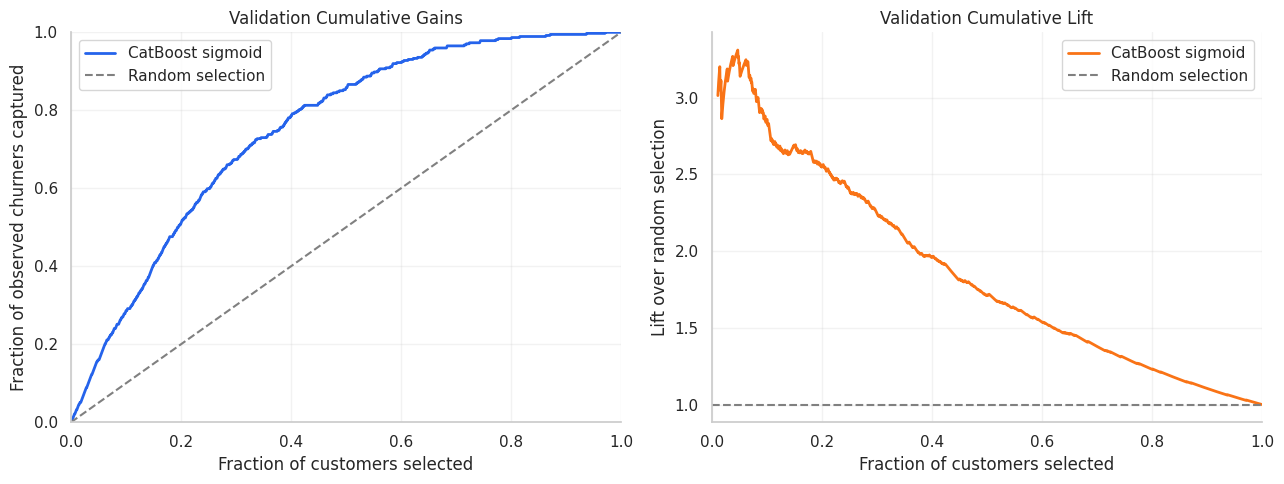

In [36]:
coverage = (
    validation_ranking["RiskRank"].to_numpy() / n_customers
)

cumulative_churners = (
    validation_ranking["ActualChurn"].cumsum().to_numpy()
)

cumulative_capture = cumulative_churners / total_churners
cumulative_lift = cumulative_capture / coverage

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    np.r_[0, coverage],
    np.r_[0, cumulative_capture],
    color="#2563EB",
    linewidth=2,
    label=selected_probability_name,
)
axes[0].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Random selection",
)

axes[0].set_title("Validation Cumulative Gains")
axes[0].set_xlabel("Fraction of customers selected")
axes[0].set_ylabel("Fraction of observed churners captured")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)

plot_mask = coverage >= 0.01

axes[1].plot(
    coverage[plot_mask],
    cumulative_lift[plot_mask],
    color="#F97316",
    linewidth=2,
    label=selected_probability_name,
)
axes[1].axhline(
    1,
    linestyle="--",
    color="gray",
    label="Random selection",
)

axes[1].set_title("Validation Cumulative Lift")
axes[1].set_xlabel("Fraction of customers selected")
axes[1].set_ylabel("Lift over random selection")
axes[1].set_xlim(0, 1)

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Highest-Risk Customers: Validation Review

The table below displays customers with the highest predicted churn probabilities.

The observed churn label is included only for retrospective evaluation. It would not be available when scoring customers for future outreach.

This ranking identifies high predicted risk; it does not estimate customer responsiveness to a retention offer or the financial benefit of intervention.

In [37]:
review_columns = ["RiskRank"]

if "customerID" in validation_ranking.columns:
    review_columns.append("customerID")
else:
    review_columns.append("RowIndex")

review_columns += ["ChurnProbability", "ActualChurn"]

display(
    validation_ranking[review_columns]
    .head(20)
    .style.format({
        "ChurnProbability": "{:.2%}",
    })
)

,RiskRank,customerID,ChurnProbability,ActualChurn
0,1,0107-YHINA,94.47%,1
1,2,4912-PIGUY,90.76%,0
2,3,6521-YYTYI,90.76%,1
3,4,3988-RQIXO,89.48%,1
4,5,0723-DRCLG,88.35%,1
5,6,7503-ZGUZJ,87.65%,1
6,7,4822-RVYBB,87.47%,1
7,8,2446-BEGGB,87.36%,1
8,9,0781-LKXBR,86.90%,1
9,10,7439-DKZTW,85.88%,0


### Interpretation of Validation Results

Sigmoid calibration achieved a marginally lower validation log loss
(0.42126 versus 0.42154), while the original model retained a slightly
lower Brier score (0.13620 versus 0.13625). ROC AUC and average precision
were unchanged at the reported precision. Sigmoid calibration was
selected according to the predefined log-loss criterion, although
the observed difference is small.

The selected model concentrates observed churners near the top of
the risk ranking:

- Selecting the highest-risk 10% of customers captures 28.61% of
  validation churners, with 75.89% precision and 2.86× lift.
- Expanding coverage to 20% captures 51.07% of churners, with
  67.73% precision and 2.55× lift.
- Expanding coverage to 30% captures 67.38% of churners, while
  precision decreases to 59.57%.

These results illustrate the trade-off between contact capacity and
churn coverage. They support prioritizing customers for further
retention assessment, but do not measure whether an intervention
would prevent churn or generate a positive financial return.

The findings remain development-stage validation results. Final
performance will be assessed on the untouched test set.

## 10. Model Explainability with SHAP

Predictive performance shows how well the model identifies churn risk.
Explainability helps us understand which features contribute to its
predictions.

We will use SHAP to examine:

- **Global importance:** which features contribute most strongly across
  the customers examined.
- **Individual predictions:** which features push a customer's predicted
  churn risk higher or lower.

The SHAP analysis will explain the underlying CatBoost model's raw
prediction score. These contributions are not percentage-point changes
in the sigmoid-calibrated churn probability, and they describe model
behavior rather than causal effects.

### 10.1 Calculating and Verifying SHAP Contributions

We calculate SHAP values for validation customers using the fitted
CatBoost model.

Before generating explanations, we verify that the model reproduces
the original validation probabilities. This ensures that we are
explaining the same model predictions evaluated earlier.

For this binary classifier:

- Positive SHAP values push the raw prediction toward churn.
- Negative SHAP values push the raw prediction away from churn.
- The baseline plus all feature contributions reconstructs the
  model's raw prediction.

Contributions are expressed in raw-score (log-odds) units. They do
not directly explain the final sigmoid-calibrated probability.

In [38]:
from catboost import Pool

shap_feature_names = list(fitted_catboost.feature_names_)
X_shap = X_valid.loc[:, shap_feature_names].copy()

cat_indices = fitted_catboost.get_cat_feature_indices()

for position in cat_indices:
    column = X_shap.columns[position]

    if X_shap[column].isna().any():
        raise ValueError(
            f"{column} contains missing categorical values. "
            "Reuse the exact categorical preparation from model training."
        )

    X_shap[column] = X_shap[column].astype(str)

shap_pool = Pool(
    X_shap,
    cat_features=cat_indices,
)

original_probabilities = np.asarray(
    calibration_predictions["CatBoost original"],
    dtype=float,
).ravel()

reproduced_probabilities = fitted_catboost.predict_proba(
    shap_pool
)[:, 1]

np.testing.assert_allclose(
    reproduced_probabilities,
    original_probabilities,
    rtol=1e-6,
    atol=1e-8,
    err_msg=(
        "Predictions differ from the original validation predictions. "
        "Check the model and validation preprocessing before continuing."
    ),
)

native_shap = np.asarray(
    fitted_catboost.get_feature_importance(
        data=shap_pool,
        type="ShapValues",
    )
)

shap_values = native_shap[:, :-1]
shap_baselines = native_shap[:, -1]

raw_predictions = np.asarray(
    fitted_catboost.predict(
        shap_pool,
        prediction_type="RawFormulaVal",
    )
).ravel()

np.testing.assert_allclose(
    shap_baselines + shap_values.sum(axis=1),
    raw_predictions,
    rtol=1e-6,
    atol=1e-6,
)

print(f"Customers explained: {len(X_shap):,}")
print(f"Features explained: {X_shap.shape[1]}")
print("Original validation probabilities reproduced.")
print("SHAP contributions reconstruct the raw model predictions.")

Customers explained: 1,409
Features explained: 19
Original validation probabilities reproduced.
SHAP contributions reconstruct the raw model predictions.


### 10.2 Global Feature Importance

We summarize each feature's importance using its mean absolute
SHAP value across validation customers.

A higher value means that the feature contributes more strongly
to predictions on average. Absolute importance measures contribution
magnitude; it does not indicate whether a feature consistently
increases or decreases predicted churn risk.

These values describe the fitted model's behavior. Correlated
features can share attribution, and importance does not establish
a causal relationship with churn.

,Feature,Mean absolute SHAP
0,Contract,0.6310
1,tenure,0.4790
2,MonthlyCharges,0.3604
3,InternetService,0.2763
4,OnlineSecurity,0.2623
5,TechSupport,0.1794
6,PaymentMethod,0.1641
7,TotalCharges,0.1491
8,OnlineBackup,0.1215
9,PaperlessBilling,0.1199


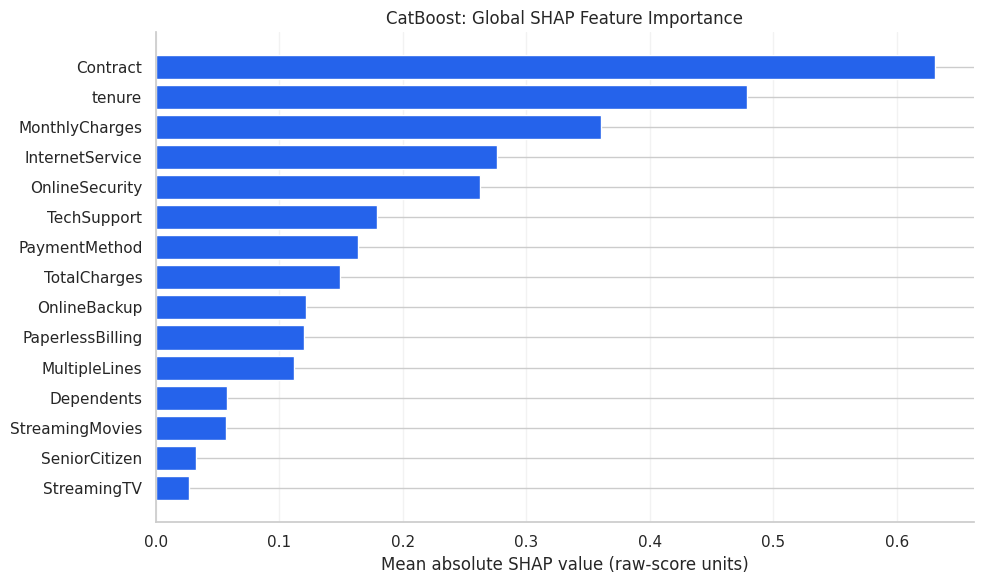

In [39]:
shap_importance = (
    pd.DataFrame({
        "Feature": shap_feature_names,
        "Mean absolute SHAP": np.abs(shap_values).mean(axis=0),
    })
    .sort_values("Mean absolute SHAP", ascending=False)
    .reset_index(drop=True)
)

display(
    shap_importance.style.format({
        "Mean absolute SHAP": "{:.4f}",
    })
)

plot_importance = shap_importance.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    plot_importance["Feature"],
    plot_importance["Mean absolute SHAP"],
    color="#2563EB",
)

ax.set_title("CatBoost: Global SHAP Feature Importance")
ax.set_xlabel("Mean absolute SHAP value (raw-score units)")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### 10.3 Explaining an Individual High-Risk Customer

We examine the customer with the highest selected churn probability
to understand the features contributing to the underlying CatBoost
prediction.

The table reports the customer's feature values and signed SHAP
contributions. Orange bars push the raw prediction toward churn;
blue bars push it away from churn.

The chart displays the ten largest contributions by absolute
magnitude. The complete set of contributions, together with the
baseline, reconstructs the raw prediction.

The explanation identifies model-associated risk factors. It does
not demonstrate that changing those features would prevent churn.

Validation row index: 1704
Customer ID: 0107-YHINA
Original CatBoost probability: 95.19%
Selected probability (CatBoost sigmoid): 94.47%
Raw-score baseline: -1.6673
Raw prediction: 2.9860


,Feature,Customer value,SHAP contribution
4,tenure,1.000000,+1.5252
17,MonthlyCharges,99.750000,+0.9933
14,Contract,Month-to-month,+0.5326
7,InternetService,Fiber optic,+0.3370
8,OnlineSecurity,No,+0.2858
18,TotalCharges,99.750000,+0.2476
16,PaymentMethod,Electronic check,+0.2139
11,TechSupport,No,+0.1954
9,OnlineBackup,No,+0.1680
6,MultipleLines,Yes,+0.1534


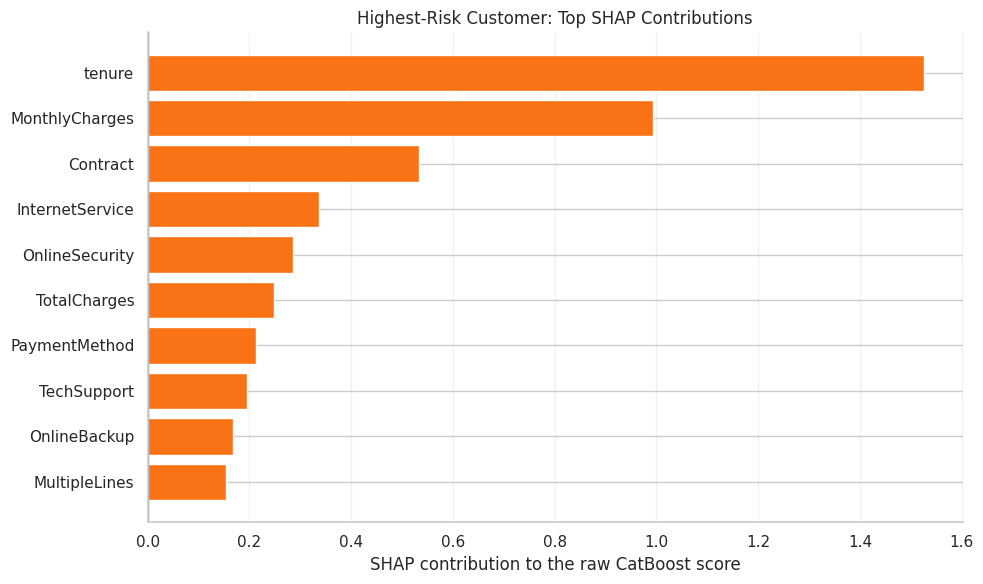

In [40]:
customer_position = int(
    np.argmax(selected_valid_probabilities)
)

customer_index = X_shap.index[customer_position]

local_explanation = pd.DataFrame({
    "Feature": shap_feature_names,
    "Customer value": X_shap.iloc[customer_position].to_numpy(),
    "SHAP contribution": shap_values[customer_position],
})

local_explanation["Absolute contribution"] = (
    local_explanation["SHAP contribution"].abs()
)

local_explanation = local_explanation.sort_values(
    "Absolute contribution",
    ascending=False,
)

print(f"Validation row index: {customer_index}")

if "customerID" in valid_df.columns:
    print(
        "Customer ID:",
        valid_df.loc[customer_index, "customerID"],
    )

print(
    "Original CatBoost probability:",
    f"{reproduced_probabilities[customer_position]:.2%}",
)
print(
    f"Selected probability ({selected_probability_name}):",
    f"{selected_valid_probabilities[customer_position]:.2%}",
)
print(
    "Raw-score baseline:",
    f"{shap_baselines[customer_position]:.4f}",
)
print(
    "Raw prediction:",
    f"{raw_predictions[customer_position]:.4f}",
)

display(
    local_explanation[
        ["Feature", "Customer value", "SHAP contribution"]
    ].style.format({
        "SHAP contribution": "{:+.4f}",
    })
)

local_plot = local_explanation.head(10).iloc[::-1]

colors = [
    "#F97316" if value > 0 else "#2563EB"
    for value in local_plot["SHAP contribution"]
]

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    local_plot["Feature"],
    local_plot["SHAP contribution"],
    color=colors,
)

ax.axvline(0, color="gray", linewidth=1)
ax.set_title("Highest-Risk Customer: Top SHAP Contributions")
ax.set_xlabel("SHAP contribution to the raw CatBoost score")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### 10.4 Interpretation of SHAP Results

Contract type and tenure have the largest mean absolute SHAP values
across validation customers. Monthly charges, internet service, and
online security also contribute prominently to the fitted model's
predictions.

These global importance values measure contribution magnitude.
They do not establish which category or feature value increases
risk for every customer.

For the highest-risk customer examined, tenure and monthly charges
provide the strongest positive contributions toward churn. Contract
type and several service-related features also push the prediction
toward higher risk.

The verification checks confirmed that:

- The explanation inputs reproduce the original CatBoost validation
  probabilities.
- The baseline plus all SHAP contributions reconstructs each
  customer's raw model prediction.

These explanations describe the underlying CatBoost model in
raw-score units. They are not percentage-point contributions to
the sigmoid-calibrated probability and do not establish causal
effects or the effectiveness of retention interventions.

## 11. Final Held-Out Test Evaluation

We now evaluate the previously selected probability model on the
held-out test customers.

Model parameters and the calibration choice are fixed before this
evaluation. The existing models and sigmoid mapping are applied
without refitting or using test outcomes to change the approach.

For context, we also report the training-prevalence benchmark,
logistic regression and original CatBoost. These comparisons do not
reopen model selection.

Evaluation covers:

- **Discrimination:** ROC AUC and average precision.
- **Probability quality:** log loss and Brier score.
- **Prioritization:** churn capture and lift at predefined contact capacities.

Because customers were randomly partitioned, these results assess
generalisation to held-out customers from this sample. They do not
demonstrate performance on future customers or another telecom population.

In [41]:
final_probability_name = selected_probability_name

X_test = test_df[model_features].copy()
y_test = test_df["ChurnFlag"].copy()

for column in model_categorical:
    X_test[column] = (
        X_test[column]
        .astype(object)
        .where(X_test[column].notna(), np.nan)
    )

X_test_cat = X_test.copy()

for column in model_categorical:
    X_test_cat[column] = (
        X_test_cat[column]
        .astype("string")
        .fillna("__MISSING__")
        .astype(str)
    )

assert X_test.columns.equals(X_train.columns)
assert X_test_cat.columns.equals(X_train_cat.columns)

reproduced_valid_calibrated = sigmoid_calibrator.predict_proba(
    np.asarray(valid_raw_scores).reshape(-1, 1)
)[:, 1]

np.testing.assert_allclose(
    reproduced_valid_calibrated,
    calibration_predictions["CatBoost sigmoid"],
    rtol=1e-6,
    atol=1e-8,
)

test_original_probabilities = fitted_catboost.predict_proba(
    X_test_cat
)[:, 1]

test_raw_scores = fitted_catboost.predict(
    X_test_cat,
    prediction_type="RawFormulaVal",
)

test_calibrated_probabilities = sigmoid_calibrator.predict_proba(
    np.asarray(test_raw_scores).reshape(-1, 1)
)[:, 1]

test_predictions = {
    "Prevalence benchmark": np.full(
        len(y_test),
        float(y_train.mean()),
    ),
    "Logistic regression": fitted_logistic.predict_proba(
        X_test
    )[:, 1],
    "CatBoost original": test_original_probabilities,
    "CatBoost sigmoid": test_calibrated_probabilities,
}

selected_test_probabilities = test_predictions[
    final_probability_name
].copy()

test_rows = []

for name, probabilities in test_predictions.items():
    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()

    test_rows.append({
        "Model": name,
        "Selected on validation": name == final_probability_name,
        "ROC AUC": roc_auc_score(y_test, probabilities),
        "Average precision": average_precision_score(
            y_test, probabilities
        ),
        "Log loss": log_loss(
            y_test, probabilities, labels=[0, 1]
        ),
        "Brier score": brier_score_loss(y_test, probabilities),
    })

test_results = pd.DataFrame(test_rows).set_index("Model")

print(f"Test customers: {len(y_test):,}")
print(f"Test churn rate: {y_test.mean():.2%}")
print(f"Previously selected model: {final_probability_name}")

display(
    test_results.style.format({
        "ROC AUC": "{:.5f}",
        "Average precision": "{:.5f}",
        "Log loss": "{:.5f}",
        "Brier score": "{:.5f}",
    })
)

Test customers: 1,409
Test churn rate: 26.54%
Previously selected model: CatBoost sigmoid


,Selected on validation,ROC AUC,Average precision,Log loss,Brier score
Model,,,,,
Prevalence benchmark,False,0.50000,0.26544,0.57867,0.19498
Logistic regression,False,0.84285,0.63423,0.41973,0.13773
CatBoost original,False,0.84782,0.67166,0.41333,0.13431
CatBoost sigmoid,True,0.84782,0.67166,0.41325,0.13434


### 11.1 Customer Prioritization on Held-Out Data

We assess the selected model at the same contact capacities examined
during validation: 5%, 10%, 20%, 30% and 50%.

Customers are ranked by predicted churn probability. For each capacity,
we report the number selected, observed churners captured, precision,
churn capture and lift over random selection.

These capacities represent alternative operational scenarios. No single
capacity is declared optimal because intervention costs, customer value
and treatment effectiveness are unavailable.

The results evaluate risk concentration, not churn prevention or
financial returns.

In [42]:
test_ranking = pd.DataFrame({
    "customerID": test_df.loc[X_test.index, "customerID"].to_numpy(),
    "ActualChurn": y_test.to_numpy(),
    "ChurnProbability": selected_test_probabilities,
})

test_ranking = (
    test_ranking
    .sort_values(
        "ChurnProbability",
        ascending=False,
        kind="stable",
    )
    .reset_index(drop=True)
)

test_ranking["RiskRank"] = np.arange(
    1, len(test_ranking) + 1
)

test_total_churners = int(test_ranking["ActualChurn"].sum())
test_prevalence = test_ranking["ActualChurn"].mean()

if test_total_churners == 0:
    raise ValueError("Churn capture requires observed churners.")

test_capacity_rows = []

for capacity in [0.05, 0.10, 0.20, 0.30, 0.50]:
    n_selected = int(np.ceil(capacity * len(test_ranking)))
    selected_group = test_ranking.iloc[:n_selected]

    churners_captured = int(selected_group["ActualChurn"].sum())
    precision = churners_captured / n_selected

    test_capacity_rows.append({
        "Target capacity": f"Top {capacity:.0%}",
        "Customers selected": n_selected,
        "Actual coverage": n_selected / len(test_ranking),
        "Churners captured": churners_captured,
        "Precision": precision,
        "Churn capture": churners_captured / test_total_churners,
        "Lift": precision / test_prevalence,
    })

test_capacity_results = pd.DataFrame(test_capacity_rows)

display(
    test_capacity_results.style.format({
        "Actual coverage": "{:.1%}",
        "Precision": "{:.2%}",
        "Churn capture": "{:.2%}",
        "Lift": "{:.2f}×",
    })
)

,Target capacity,Customers selected,Actual coverage,Churners captured,Precision,Churn capture,Lift
0,Top 5%,71,5.0%,59,83.10%,15.78%,3.13×
1,Top 10%,141,10.0%,108,76.60%,28.88%,2.89×
2,Top 20%,282,20.0%,195,69.15%,52.14%,2.61×
3,Top 30%,423,30.0%,253,59.81%,67.65%,2.25×
4,Top 50%,705,50.0%,322,45.67%,86.10%,1.72×


### 11.2 Interpretation of Held-Out Test Results

The previously selected sigmoid-calibrated CatBoost model achieved
the following results across 1,409 held-out customers:

| Metric | Test result |
|---|---:|
| ROC AUC | 0.84782 |
| Average precision | 0.67166 |
| Log loss | 0.41325 |
| Brier score | 0.13434 |

These results are broadly consistent with validation performance,
where ROC AUC was 0.84111 and average precision was 0.65378.
There is no obvious deterioration on this held-out split.

CatBoost performed better than logistic regression on all four
reported test metrics. These point estimates do not establish
statistical significance.

Sigmoid calibration made only a small difference: test log loss
decreased from 0.41333 to 0.41325, while Brier score increased
slightly from 0.13431 to 0.13434. Ranking metrics remained unchanged
at the reported precision. The calibration choice remains the one
made using validation data.

#### Prioritization Performance

The overall test churn rate was 26.54%. Ranking customers by the
selected model's probabilities concentrated observed churners near
the top:

| Customers selected | Precision | Churn capture | Lift |
|---|---:|---:|---:|
| Top 5% | 83.10% | 15.78% | 3.13× |
| Top 10% | 76.60% | 28.88% | 2.89× |
| Top 20% | 69.15% | 52.14% | 2.61× |
| Top 30% | 59.81% | 67.65% | 2.25× |
| Top 50% | 45.67% | 86.10% | 1.72× |

For example, selecting the highest-risk 20% identifies 195 of the
374 observed churners within a group of 282 customers.

This demonstrates useful risk concentration within the held-out
sample. It does not mean that contacting those customers would
prevent their churn.

## 12. Conclusions and Limitations

### Main Findings

This notebook combined data-quality checks, statistical analysis,
customer segmentation, predictive modelling, probability calibration
and SHAP explanations.

- **Customer characteristics:** Training-sample churn was associated
  with contract type, shorter tenure and higher monthly charges.
  These comparisons were exploratory and unadjusted.

- **Customer segmentation:** Four exploratory customer profiles
  showed high assignment stability under the tested subsampling
  procedure. Shorter-tenure fibre customers had the highest observed
  training-segment churn rate.

- **Predictive performance:** The selected CatBoost approach achieved
  a held-out ROC AUC of 0.84782 and average precision of 0.67166,
  improving on the logistic regression benchmark.

- **Probability calibration:** Sigmoid calibration changed probability
  quality only marginally. Its small log-loss improvement was
  accompanied by a slightly worse Brier score.

- **Explainability:** Contract type and tenure had the largest mean
  absolute SHAP contributions across validation customers, followed
  by monthly charges and service-related characteristics.

- **Customer prioritization:** The highest-risk 20% of test customers
  contained 52.14% of observed churners, demonstrating how risk
  ranking can support capacity-constrained customer review.

### Limitations

- The dataset represents a fictional telecom company. Results should
  not be assumed to transfer directly to a real customer population.
- Random splitting evaluates held-out customers from this sample,
  rather than performance across future time periods.
- Reported test metrics are point estimates from one split;
  uncertainty intervals and external validation were not included.
- Clusters depend on feature selection, scaling and encoding.
  Their stability assessment held preprocessing fixed.
- Statistical associations and SHAP contributions do not establish
  causal effects.
- The data does not identify which customers would respond to an
  intervention. Customer value, intervention costs and treatment
  effectiveness would be needed to evaluate financial returns.

### Practical Next Step

A real-world extension would define a prediction date and future
churn horizon, validate on later customer cohorts, and assess retention
interventions through a controlled experiment.

The current analysis provides evidence for customer-risk ranking
and investigation within this dataset.